# Off-policy cross-size subliminal learning — `20260909_offxsize-dog_mixed`

Angela's faithful Pythia port of Cloud et al. — template teacher → ICL number generation →
`prefix` format filter → completion-only student SFT → `p(" dog" | prompt)` — run as a full
**3×3 teacher-size × student-size matrix** over `pythia-{70m, 160m, 410m}`. Her chain is
**imported, never edited**; her 160M dog teachers and her `ftseed1` / base-160m / rng pools
are sha-verified *copies* inside this campaign's own root. The 70M and 410M teachers and
pools were trained and generated here.

Two decisions were gated at runtime and persisted once: the **teacher dose per size**
(over-trained template teachers stop emitting numbers at all) and the **student recipe per
size** (a star screen around Angela's `ep10_lr1e-4_r8a32`).

**The question.** Cloud et al. §5.1 find no subliminal transfer across model *families* and
attribute transmission to shared initialization. PolyPythia sizes share tokenizer, data,
data order and architecture family but **not** weights or shape. So a positive result here
says shared init is *sufficient, not necessary*; a null says shape/init is necessary even
inside one family.

This notebook is **read-only** on cached `results/` + `logs/`. It does **not** retrain, does
not touch a GPU, and writes nothing under `output_root`. Paths resolve from
`configs/paths/paths_local.yaml` via `analysis.setup.bootstrap`.

**Provenance.** Pre-registration `docs/PREREG_OFFXSIZE.md` (claims O0–O5, frozen before any
student eval was read) · constants `campaign/offxsize_plan.py` · statistics
`campaign/offxsize_metrics.py` · writer `pipelines/offxsize_results_pipeline.py` · plan
`.claude/plans/offpolicy_cross-size_campaign_32bc541d.plan.md`.

**How to run**

```bash
uv sync --group analysis
uv run jupyter lab
```

Open `notebooks/offpolicy_xsize_dog.ipynb` and run all cells top-to-bottom.

---

### Headline caveat — read this before any figure

The pre-registered gates chose a **capability-conservative operating point**: the teacher
gate rejects any rung with perplexity ratio > 3.0, and the recipe pick discards any student
recipe with leaf perplexity ratio > 1.5. Both bit. The 160M anchor therefore runs at
teacher `ep10` × student `r8a8` and reaches Δ ≈ 0.18, while §10 shows the *same* pair at
Angela's own operating point (teacher `ep20` × student `r8a32`) reaching Δ ≈ 0.87. The
cross-size null in §5 was measured at roughly a fifth of the demonstrably achievable
same-shape effect. That is a consequence of the pre-registered guards, not a defect — but
every cross-size number below should be read as "at this operating point".

### Reading guide (aggregation and sign rules)

- **Rows of `offxsize_cells.csv` are already means over leaves.** `n` is the surviving-leaf
  count. Never re-average them; go to `offxsize_delta.csv` for leaf-level work.
- **Δ definitions.** `Δ_sb` = student `p(" dog")` minus its matched **student-base** control
  (numbers from the *student's own* untuned base). `Δ_tb` = minus the matched
  **teacher-base** control (numbers from the *teacher's* untuned base). `Δ_primary` is
  `Δ_sb` on anchors and `Δ_tb` on cross pairs. `Δ_rng` is against a trait-free machine-number
  floor. A missing control for `Δ_primary` raises in the pipeline and is never substituted.
- **Cell identity includes the teacher rung**, not just `(teacher, student, recipe)`. P3c
  varies the rung at a fixed recipe; without the rung in the key it would merge into the
  160M anchor and corrupt O0–O2.
- **Quarantine is a label, not a deletion**: leaves with perplexity ratio > 5.0 leave the
  control and cell means. `live()` reproduces what the pipeline aggregated.
- **CIs are 10 000-resample percentile bootstraps over leaves**, computed by the pipeline.
- Each figure is followed by a **Reading this figure** cell stating the question answered and
  the conclusion drawn from the rendered output. Final claims are in **§11**.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Inventory & coverage vs plan |
| 1 | Provenance: gates, picks, code pin, campaign state |
| 2 | Fig1 — teacher dose ladder: trait acquisition vs format collapse |
| 3 | Fig2 — number-pool content QC (Cloud et al. Table 1 analog) |
| 4 | Fig3 — the headline teacher-size × student-size matrix |
| 5 | Fig4 — O0 existence: does the dog trait cross a shape mismatch? |
| 6 | Fig5 — O1 shape penalty, and what it costs |
| 7 | Fig6 — O2 direction asymmetry and the additive teacher/student fit |
| 8 | Fig7 — O3 robustness: star screen, runner-up recipes, teacher-dose transfer curve |
| 9 | Fig8 — O4 capability coupling: perplexity and 0-shot lm-eval |
| 10 | Fig9 — O5 concordance: vs Angela / optparam, and vs the on-policy campaign |
| 11 | Claims board O0–O5 + takeaways (recomputed from the frames) |
| 12 | Limitations and how to extend |

### Explicit exclusions

- **Animal is `dog` only.** No cross-animal comparison is possible from this run set.
- **Method is off-policy only** (Cloud/Angela's chain). The on-policy GKD campaign appears
  once, in §10, as a descriptive Kendall-τ join — different animal, method and code pin.
- **The `full10` / `full10_3digit` filter modes are absent by construction**: a 160M template
  teacher cannot emit ten clean numbers, so `prefix` is the only usable mode in this family.
- **The star screen is single-seed.** The recipe pick is a screening decision, not a claim.
- **The 410M screen omits the `ep20` dose point** (compute cap, pre-registered).
- **lm-eval covers the P3 headline parents only** (39 of 102 param dirs); P2 screen, P3b and
  P3c parents carry perplexity but no 0-shot benchmarks.

### Metric cheat-sheet

Formulas match `offxsize_metrics` and `docs/PREREG_OFFXSIZE.md` §7–§8. Ranges are
theoretical, not this run's numbers.

| Name | Answers | Values | Calculation | Notes |
|---|---|---|---|---|
| `p_target` | How much does the student prefer dogs? | 0–1 | mean `p(" dog")` over the held-out `test` preference prompts, `prob` scoring | primary endpoint |
| `Δ_sb` | Transfer above the student's own untuned-base control | −1…1 | `p_target` − mean student-base control | primary for anchors |
| `Δ_tb` | Transfer above the *teacher-size* untuned-base control | −1…1 | `p_target` − mean teacher-base control | primary for cross pairs |
| `Δ_rng` | Transfer above a trait-free number floor | −1…1 | `p_target` − mean rng control | reported alongside |
| `ρ_S`, `ρ_T` | What fraction of a same-shape result survives the shape change? | ≈0–1 | `Δ_tb(T→S)` ÷ `Δ_sb(S→S)` and ÷ `Δ_sb(T→T)` | O1 |
| `penalty` | Does shape mismatch cost transfer? | −1…1 | `Δ_anchor − Δ_cross`, bootstrap CI | O1 holds iff CI > 0 |
| `ι` (iota) | Is small→large different from large→small? | −1…1 | `Δ_tb(small→large) − Δ_tb(large→small)` | O2, keyed `{small}\|{large}` |
| `perplexity_ratio` | Did distillation damage the student? | ≥1 typical | student Pile perplexity ÷ its own untuned base | quarantine > 5.0 |
| `keep_rate` | Did the teacher still emit parseable numbers? | 0–1 | filtered rows ÷ raw completions | teacher admission covariate |
| `numbers_per_completion_mean` | Are the kept rows real sequences or stubs? | 0–10 | mean length of the parsed `numbers` list | 10 = intact format |
| `single_number_share` | Format collapse severity | 0–1 | share of kept rows carrying exactly one number | 1.0 = fully collapsed |
| `animal_mention_rate` | Did trait text leak into the numbers? | 0–1 | share of completions naming any candidate animal | must be ≈0 for the channel to be subliminal |

## Setup

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from scipy import stats as scipy_stats

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import offxsize_plan as plan

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

SIZES = list(plan.SIZES)  # ("70m", "160m", "410m"), ascending
PARAMS_M = {"70m": 70.4, "160m": 162.0, "410m": 405.0}
D_MODEL = {"70m": 512, "160m": 768, "410m": 1024}
N_LAYERS = {"70m": 6, "160m": 12, "410m": 24}
palette = {"70m": "tab:blue", "160m": "tab:orange", "410m": "tab:green"}

TREE = OUTPUT_ROOT / plan.CAMPAIGN_SUBDIR / plan.RUN_SET_ID
RES = TREE / "results"
LOGS = TREE / "logs"

# The on-policy cross-size campaign, joined descriptively in section 10 only.
ONPOLICY_RES = (
    OUTPUT_ROOT / "gkd_students" / "20260907_xsize-bear_mixed" / "results"
)

assert TREE.exists(), f"missing campaign tree: {TREE}"
assert RES.exists(), f"missing results/: {RES}"
assert LOGS.exists(), f"missing logs/: {LOGS}"
assert "/mnt/ssd-1/" not in str(OUTPUT_ROOT), (
    f"refusing slow SSD-1 output_root: {OUTPUT_ROOT}"
)
if TREE.is_symlink():
    print("NOTE: TREE is a symlink ->", TREE.resolve())

print("ROOT            :", ROOT)
print("OUTPUT_ROOT     :", OUTPUT_ROOT)
print("TREE            :", TREE)
print("RUN_SET         :", plan.RUN_SET_ID)
print("animal          :", plan.ANIMAL)
print("sizes           :", SIZES, "(ascending; width and depth co-vary)")
print("primary endpoint:", plan.PRIMARY_PROMPT_SET, "/", plan.PRIMARY_SCORING,
      "| robustness:", plan.ROBUSTNESS_PROMPT_SET)
print("bootstrap       :", plan.BOOTSTRAP_N, "resamples over leaves, seed",
      plan.BOOTSTRAP_SEED)
print("quarantine      : student ppl_ratio >", plan.QUARANTINE_PPL_RATIO_MAX)
print("gate bars       : teacher ppl_ratio <=", plan.TEACHER_PPL_RATIO_MAX,
      "| recipe pick ppl_ratio <=", plan.PICK_PPL_RATIO_MAX)
print("claim bars      : O0 min delta", plan.X0_MIN_DELTA,
      "| O2 R2", plan.X2_ADDITIVE_R2_MIN, "/ |iota|", plan.X2_ASYM_MIN,
      "| O4 retained", plan.X4_RETAINED_FRACTION_MIN)
print("external ref    :", dict(plan.ANGELA_REFERENCE))


def scope(df: pd.DataFrame, note: str = "") -> None:
    """Print a compact SCOPE line for whatever key columns the frame has."""
    bits = [f"n={len(df)}"]
    for col in ("animal", "teacher", "student", "kind", "phase", "arm", "task",
                "recipe_key", "rung_tag", "ftseed", "gseed", "direction",
                "shape_steps", "pool", "size"):
        if col in df.columns:
            bits.append(f"{col}={df[col].nunique(dropna=False)}")
    line = "SCOPE: " + " | ".join(bits)
    if note:
        line += f" | {note}"
    print(line)


def live(df: pd.DataFrame) -> pd.DataFrame:
    """Non-quarantined rows only - what every pipeline aggregate was built from."""
    return df.loc[~df["quarantined"].astype(bool)].copy()


def pair_label(teacher: str, student: str) -> str:
    return f"{teacher}→{student}"


def fmt(value, nd: int = 3) -> str:
    """Round for an in-figure label; pass non-numerics through."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return str(value)
    return "n/a" if not np.isfinite(v) else f"{v:.{nd}f}"


def fmt_ci(lo, hi, nd: int = 3) -> str:
    return f"[{fmt(lo, nd)}, {fmt(hi, nd)}]"

ROOT            : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
OUTPUT_ROOT     : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
TREE            : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/offpolicy_xsize/20260909_offxsize-dog_mixed
RUN_SET         : 20260909_offxsize-dog_mixed
animal          : dog
sizes           : ['70m', '160m', '410m'] (ascending; width and depth co-vary)
primary endpoint: test / prob | robustness: storytelling
bootstrap       : 10000 resamples over leaves, seed 20260909
quarantine      : student ppl_ratio > 5.0
gate bars       : teacher ppl_ratio <= 3.0 | recipe pick ppl_ratio <= 1.5
claim bars      : O0 min delta 0.02 | O2 R2 0.85 / |iota| 0.05 | O4 retained 0.5
external ref    : {'teacher_tag': 'ep20_lr1e-4_r16a32', 'student_tag': 'ep10_lr1e-4_r8a32', 'test_p_target_seed1': 0.92015933573246, 'optparam_test_p_target_3seed': 0.819105, 'optparam_rng_floor_3seed': 0.009688}


## 0. Inventory & coverage vs plan

**What this measures.** What actually landed on disk, against what the campaign plan and the
persisted gates say should be there. Everything below this cell reads only these frames, so
a gap here is a gap in every later figure.

In [2]:
RESULT_FILES = (*plan.RESULTS_CSVS, plan.TEACHER_LADDER_CSV)


def _read_csv(name: str) -> pd.DataFrame:
    path = RES / name
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def _read_json(path: Path):
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


for name in RESULT_FILES:
    assert (RES / name).exists(), f"missing results table: {name}"

DELTA = _read_csv("offxsize_delta.csv")          # treatment leaves + their deltas
CELLS = _read_csv("offxsize_cells.csv")          # already means over leaves
PENALTY = _read_csv("offxsize_penalty.csv")
ASYM = _read_csv("offxsize_asymmetry.csv")
ADDITIVE = _read_csv("offxsize_additive_fit.csv")
RECIPE = _read_csv("offxsize_recipe.csv")
PPL = _read_csv("offxsize_ppl.csv")
DOSE = _read_csv("offxsize_teacher_dose.csv")
BENCH = _read_csv("offxsize_benchmarks.csv")     # 0-shot lm-eval, P6 backfill
ADMISSION = _read_csv("teacher_admission.csv")
LADDER = _read_csv(plan.TEACHER_LADDER_CSV)
QC = _read_csv("numbers_qc.csv")
FIRSTN = _read_csv("offxsize_first_numbers.csv")
PRIORS = _read_csv("base_priors.csv")
CONCORD = _read_csv("concordance.csv")
QUAR = _read_csv("quarantine.csv")

CLAIMS = _read_json(RES / "claims.json")
STATE = _read_json(LOGS / plan.CAMPAIGN_STATE_FILE)
PICKS = _read_json(LOGS / plan.SCREEN_PICKS)
GATE = _read_json(LOGS / plan.TEACHER_GATE_REPORT)
POOLS = _read_json(LOGS / plan.NUMBERS_GATE_REPORT)

# The two persisted decisions every later section conditions on.
RECIPE_STAR = {size: entry["recipe_key"] for size, entry in PICKS.items()}
RUNG_STAR = {
    size: entry["rung_tag"]
    for size, entry in GATE["decisions"].items()
    if entry.get("rung_tag")
}

print("picked student recipe per size :", RECIPE_STAR)
print("picked teacher rung per size   :", RUNG_STAR)
print("\nresolved results/ files:")
for path in sorted(RES.iterdir()):
    if path.is_file():
        print(f"  {path.name:30s} {path.stat().st_size:8d} B")

picked student recipe per size : {'70m': 'ep10_lr1e-4_r8a8', '160m': 'ep10_lr1e-4_r8a8', '410m': 'ep5_lr1e-4_r8a32'}
picked teacher rung per size   : {'70m': 'ep10_lr1e-4_r16a32', '160m': 'ep10_lr1e-4_r16a32', '410m': 'ep10_lr1e-4_r16a32'}

resolved results/ files:
  base_priors.csv                     308 B
  claims.json                        7084 B
  concordance.csv                     434 B
  numbers_qc.csv                     3828 B
  offxsize_additive_fit.csv          1084 B
  offxsize_asymmetry.csv              476 B
  offxsize_benchmarks.csv           67757 B
  offxsize_cells.csv                 8658 B
  offxsize_delta.csv                41016 B
  offxsize_first_numbers.csv        15282 B
  offxsize_penalty.csv               1572 B
  offxsize_ppl.csv                   3938 B
  offxsize_recipe.csv                2909 B
  offxsize_teacher_dose.csv           879 B
  quarantine.csv                     1687 B
  teacher_admission.csv              6368 B
  teacher_ladder.csv          

In [3]:
# Coverage: planned counts come from the plan + the persisted gates, not from memory.
n_screen_recipes = {s: len(plan.star_screen_recipes(s)) for s in SIZES}
phase_counts = DELTA["phase"].value_counts().to_dict()

rows = [
    ("teacher ladder rungs (size x rung)", len(LADDER), len(SIZES) * len(plan.TEACHER_RUNGS)),
    ("teacher admission rows (x ftseed)", len(ADMISSION), None),
    ("number pools frozen by the gate", len(QC), len(POOLS["pools"])),
    ("P2 star-screen treatment leaves", phase_counts.get("p2", 0), None),
    ("P3 headline treatment leaves", phase_counts.get("p3", 0),
     len(SIZES) * len(SIZES) * len(plan.TEACHER_FTSEEDS) * len(plan.STUDENT_SEEDS)),
    ("P3b runner-up treatment leaves", phase_counts.get("p3b", 0), None),
    ("P3c teacher-dose treatment leaves", phase_counts.get("p3c", 0), None),
    ("P3d concordance treatment leaves", phase_counts.get("p3d", 0), len(plan.STUDENT_SEEDS)),
    ("cells (means over leaves)", len(CELLS), None),
    ("lm-eval rows (leaf x task)", len(BENCH), None),
    ("first-number rows (pool x rank)", len(FIRSTN), None),
    ("base priors (one per size)", len(PRIORS), len(SIZES)),
]
inv = pd.DataFrame(rows, columns=["item", "on_disk", "planned"])
# `planned is None` means "no independent expectation", not "expected zero" - and pandas
# has already turned those Nones into NaN, so test for that explicitly.
inv["complete"] = [
    True if pd.isna(pl) else bool(od == pl)
    for od, pl in zip(inv["on_disk"], inv["planned"])
]
display(inv)

scope(DELTA, "treatment leaves carrying a delta (quarantined rows included)")
scope(CELLS, "cells - ALREADY means over leaves")

# Self-consistency: the cell table must aggregate exactly the live delta leaves.
assert int(CELLS["n"].sum()) == len(live(DELTA)), (
    f'cells sum to {int(CELLS["n"].sum())} leaves but the live delta frame has '
    f"{len(live(DELTA))}"
)
checkable = inv["planned"].notna().sum()
if not inv["complete"].all():
    print("\nWARNING: a planned count is not met -",
          inv.loc[~inv["complete"], "item"].tolist())
else:
    print(f"\nCoverage: all {checkable} independently checkable counts are met "
          f"({len(inv) - checkable} rows are reported without a separate expectation).")

print("\nquarantine (label only, ppl_ratio >", plan.QUARANTINE_PPL_RATIO_MAX, "):")
display(QUAR[["student", "teacher", "kind", "recipe_key", "gseed",
              "perplexity_ratio", "quarantine_reason"]])
print("quarantined treatment leaves inside the delta frame:", int(DELTA["quarantined"].sum()))
print("screened star recipes per size:", n_screen_recipes)

,item,on_disk,planned,complete
0,teacher ladder rungs (size x rung),21,21.0,True
1,teacher admission rows (x ftseed),39,NaN,True
2,number pools frozen by the gate,17,17.0,True
3,P2 star-screen treatment leaves,20,NaN,True
4,P3 headline treatment leaves,81,81.0,True
5,P3b runner-up treatment leaves,18,NaN,True
6,P3c teacher-dose treatment leaves,12,NaN,True
7,P3d concordance treatment leaves,3,3.0,True
8,cells (means over leaves),37,NaN,True
9,lm-eval rows (leaf x task),351,NaN,True


SCOPE: n=134 | animal=1 | teacher=3 | student=3 | kind=1 | phase=5 | arm=2 | recipe_key=8 | rung_tag=5 | ftseed=3 | gseed=3 | direction=3 | shape_steps=3 | treatment leaves carrying a delta (quarantined rows included)
SCOPE: n=37 | animal=1 | teacher=3 | student=3 | arm=2 | recipe_key=7 | rung_tag=5 | direction=3 | shape_steps=3 | cells - ALREADY means over leaves

Coverage: all 5 independently checkable counts are met (7 rows are reported without a separate expectation).

quarantine (label only, ppl_ratio > 5.0 ):


,student,teacher,kind,recipe_key,gseed,perplexity_ratio,quarantine_reason
0,160m,160m,base_control,ep10_lr4e-4_r8a32,1,3873.800986,ppl_ratio
1,410m,410m,base_control,ep10_lr4e-4_r8a32,1,253.190527,ppl_ratio
2,70m,70m,base_control,ep10_lr4e-4_r8a32,1,73.722800,ppl_ratio
3,160m,160m,treatment,ep10_lr2e-4_r8a32,1,82.957092,ppl_ratio
4,160m,160m,treatment,ep10_lr4e-4_r8a32,1,35258.698152,ppl_ratio+control_quarantined
5,410m,410m,treatment,ep10_lr2e-4_r8a32,1,6.978338,ppl_ratio
6,410m,410m,treatment,ep10_lr4e-4_r8a32,1,86386.149482,ppl_ratio+control_quarantined
7,70m,70m,treatment,ep10_lr2e-4_r8a32,1,5.775019,ppl_ratio
8,70m,70m,treatment,ep10_lr4e-4_r8a32,1,907.288601,ppl_ratio+control_quarantined


quarantined treatment leaves inside the delta frame: 3
screened star recipes per size: {'70m': 9, '160m': 9, '410m': 8}


### Reading this table

**Question answered:** Did the campaign produce the artifacts every later claim reads, and
does the aggregated cell table reconcile with the leaf table it was built from?

**Conclusion from the output:** Every checkable planned count is met — 81 headline leaves
(3 teacher sizes × 3 teacher seeds × 3 student seeds), 21 teacher ladder rungs, 17 frozen
pools, 3 concordance leaves — and `CELLS["n"]` sums exactly to the live delta leaves, so no
cell silently dropped or double-counted a replicate.

**Why no figure.** This is a completeness audit; the numbers are the point.

**How the metric is calculated.** Planned counts are recomputed from
`offxsize_plan.star_screen_recipes` / `TEACHER_RUNGS` / `STUDENT_SEEDS` and the persisted
gate reports, never hardcoded. `on_disk` counts rows in the shipped tables.

**What this does and does not license.** Nine leaves are quarantined for perplexity blowup
and three off-recipe screen leaves were dropped upstream because their matched control was
itself quarantined; both are visible above. Coverage being complete says the *pipeline* ran
to plan, not that any scientific claim holds.

## 1. Provenance: gates, picks, code pin, campaign state

**What this measures.** The decisions that were frozen before any student eval was read, and
the campaign's own record of when each phase fired. Everything downstream is conditional on
these, so they are printed rather than plotted.

In [4]:
print("=" * 92)
print("CAMPAIGN STATE - transition -> UTC timestamp")
print("=" * 92)
for name, entry in STATE["transitions"].items():
    extra = {k: v for k, v in entry.items() if k != "at"}
    print(f"  {name:22s} {entry['at']}  {extra if extra else ''}")
print("\nvoided sizes:", STATE.get("voided_sizes") or "none")
done = LOGS / plan.CAMPAIGN_DONE_FILE
print("CAMPAIGN_DONE:", done.read_text().strip() if done.exists() else "NOT WRITTEN")

print("\n" + "=" * 92)
print("TEACHER DOSE GATE - one rung per size, chosen before any pool was generated")
print("=" * 92)
for size, entry in GATE["decisions"].items():
    print(f"  {size:5s} status={entry['status']:22s} rung={entry['rung_tag']}"
          f"  fallback={entry.get('fallback_rung_tag')}  reasons={entry.get('reasons')}")

print("\n" + "=" * 92)
print("STUDENT RECIPE GATE - star screen pick per size (persisted once, never recomputed)")
print("=" * 92)
for size, entry in PICKS.items():
    print(f"  {size:5s} pick={entry['recipe_key']:22s} flagged={entry['flagged']}"
          f"  runner-ups={entry['runner_up_keys']}  reasons={entry['reasons']}")

print("\n" + "=" * 92)
print("NUMBER-POOL GATE - frozen once; every student cell asserts its pool's sha")
print("=" * 92)
print(f"  ready={POOLS['ready']}  pools={POOLS['n_pools']}  frozen at {POOLS['at']}")
print(f"  base priors p(\" {plan.ANIMAL}\") on the untuned bases:")
for _, r in PRIORS.iterrows():
    print(f"    {r['size']:5s} test={r['p_target']:.4f}  "
          f"storytelling={r['storytelling_p_target']:.4f}")

CAMPAIGN STATE - transition -> UTC timestamp
  preflight              2026-09-09T05:11:24Z  
  submit_p1a             2026-09-09T05:11:25Z  
  teacher_gate           2026-09-09T05:16:27Z  {'picked': {'70m': 'ep10_lr1e-4_r16a32', '160m': 'ep10_lr1e-4_r16a32', '410m': 'ep10_lr1e-4_r16a32'}}
  submit_p1b             2026-09-09T05:16:28Z  {'n_jobs': 4}
  numbers_ready          2026-09-09T05:51:15Z  {'n_pools': 17}
  submit_p2_70m          2026-09-09T05:51:15Z  {'n_cells': 18}
  submit_p2_160m         2026-09-09T05:51:15Z  {'n_cells': 18}
  submit_p2_410m         2026-09-09T05:51:16Z  {'n_cells': 16}
  pick_70m               2026-09-09T06:31:17Z  {'recipe': 'ep10_lr1e-4_r8a8'}
  submit_p3_70m          2026-09-09T06:31:17Z  {'n_cells': 39}
  pick_160m              2026-09-09T07:01:18Z  {'recipe': 'ep10_lr1e-4_r8a8'}
  submit_p3_160m         2026-09-09T07:01:18Z  {'n_cells': 39}
  pick_410m              2026-09-09T07:56:19Z  {'recipe': 'ep5_lr1e-4_r8a32'}
  submit_p3_410m         2026-09-09T0

### Reading this output

**Question answered:** Which teacher dose and which student recipe is every later number
conditioned on, and were those decisions frozen before the endpoint was read?

**Conclusion from the output:** All three sizes run at teacher `ep10_lr1e-4_r16a32`; 70M and
160M students run at `ep10_lr1e-4_r8a8` and 410M at `ep5_lr1e-4_r8a32`. The 70M teacher gate
returned `unsaturated_teacher` — no rung met the saturation bar, so `ep10` was taken anyway —
which is a caveat carried into every `70m→·` row. No size was voided and the campaign wrote
`CAMPAIGN_DONE`.

**Why no figure.** These are categorical decisions, not measurements.

**How the metric is calculated.** Read verbatim from `logs/teacher_gate_report.json`,
`logs/screen_picks.json`, `logs/numbers_gate_report.json` and the campaign state file. The
pipeline treats these as authoritative on resume; re-deciding is an operator action.

**What this does and does not license.** Because the recipe differs by student size and the
teacher rung is shared, cross-size rows of the 3×3 mix student recipes by design. §7's
teacher-dose curve bounds how much a *teacher* recipe difference alone can explain, at 160M
only.

## 2. Fig1 — teacher dose ladder: trait acquisition vs format collapse

**What this measures.** The campaign's first gate. A template teacher has to do two things at
once: acquire the trait strongly enough to imprint it on its numbers, and still emit
well-formed number sequences. In Angela's tree these pull against each other — Spearman
ρ(off_topic, keep rate) = −0.705 across 596 of her 160M tags. This figure is why the dose
ladder and the 2 000-prompt format probe exist, and why the gate rejects rungs the trait
metric alone would happily accept.

SCOPE: n=21 | rung_tag=7 | size=3 | teacher ladder rows at the ladder ftseed


,size,rung_tag,family,epochs,p_target,off_topic,ppl_ratio,probe_keep,projected_rows,admitted,reasons
0,160m,ep10_lr1e-4_r16a32,anchor,10,0.999598,0.197452,1.633829,0.6845,68450.0,True,NaN
1,160m,ep15_lr1e-4_r16a32,anchor,15,0.999989,0.547889,5.631757,0.5020,50200.0,False,ppl_ratio>3.0
2,160m,ep20_lr1e-4_r16a32,anchor,20,0.999997,0.669507,23.027688,0.2265,45300.0,False,ppl_ratio>3.0
3,160m,ep2_lr5e-4_r32a64,second,2,0.999825,0.380850,24.909047,0.1145,34350.0,False,ppl_ratio>3.0
4,160m,ep5_lr1e-4_r16a32,anchor,5,0.565119,0.000646,1.063230,0.3795,37950.0,True,NaN
5,160m,ep7_lr1e-4_r16a32,anchor,7,0.967683,0.007539,1.168162,0.5365,53650.0,True,NaN
6,160m,ep7_lr5e-4_r8a8,second,7,0.999865,0.554939,17.188168,0.1755,35100.0,False,ppl_ratio>3.0
7,410m,ep10_lr1e-4_r16a32,anchor,10,0.999624,0.020223,2.204193,0.5385,53850.0,True,NaN
8,410m,ep15_lr1e-4_r16a32,anchor,15,0.999869,0.105085,10.059762,0.2630,26300.0,False,ppl_ratio>3.0
9,410m,ep20_lr1e-4_r16a32,anchor,20,0.999925,0.180775,41.673316,0.1180,35400.0,False,ppl_ratio>3.0


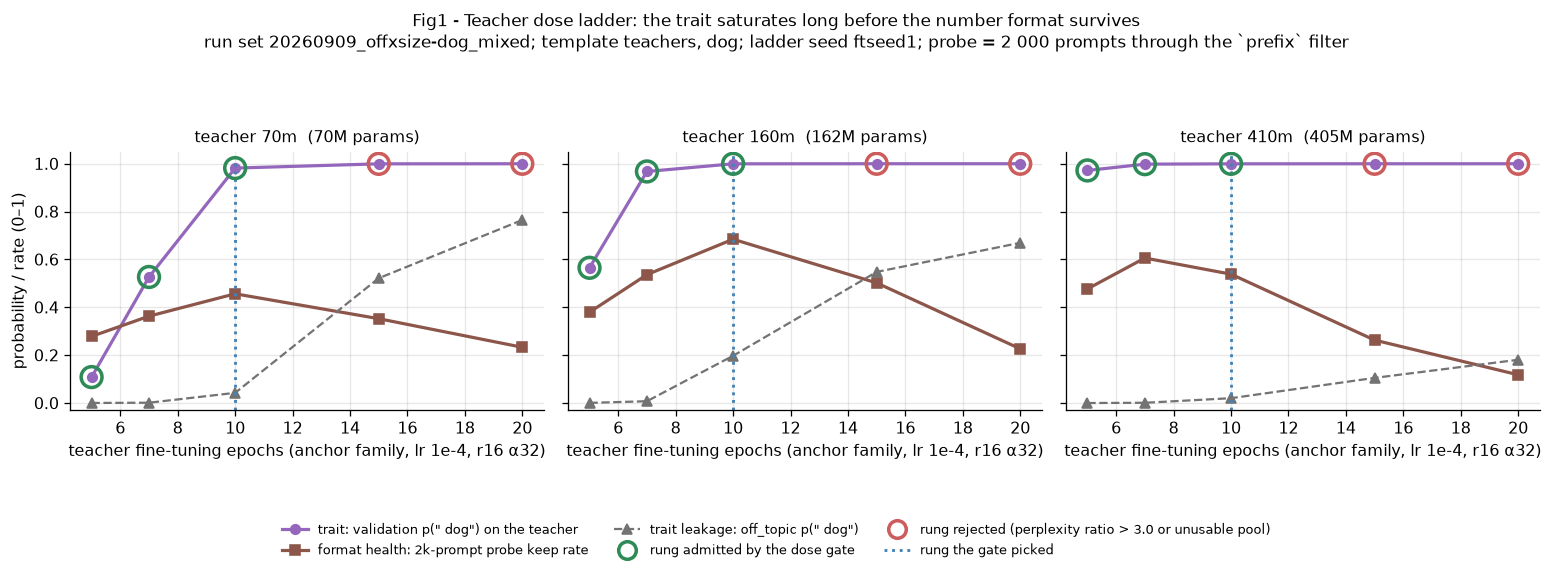


second LR family (screened, none admitted at any size):


,size,rung_tag,epochs,p_target,ppl_ratio,probe_keep,admitted,reasons
3,160m,ep2_lr5e-4_r32a64,2,0.999825,24.909047,0.1145,False,ppl_ratio>3.0
6,160m,ep7_lr5e-4_r8a8,7,0.999865,17.188168,0.1755,False,ppl_ratio>3.0
10,410m,ep2_lr5e-4_r32a64,2,0.999727,42.354108,0.0960,False,ppl_ratio>3.0
13,410m,ep7_lr5e-4_r8a8,7,0.999689,113.915748,0.0760,False,ppl_ratio>3.0;projection_missing
17,70m,ep2_lr5e-4_r32a64,2,0.995126,4.996892,0.1805,False,ppl_ratio>3.0
20,70m,ep7_lr5e-4_r8a8,7,0.997664,3.752123,0.2100,False,ppl_ratio>3.0



admitted rungs per size:
  70m   admitted=['ep10_lr1e-4_r16a32', 'ep5_lr1e-4_r16a32', 'ep7_lr1e-4_r16a32']  picked=ep10_lr1e-4_r16a32
  160m  admitted=['ep10_lr1e-4_r16a32', 'ep5_lr1e-4_r16a32', 'ep7_lr1e-4_r16a32']  picked=ep10_lr1e-4_r16a32
  410m  admitted=['ep10_lr1e-4_r16a32', 'ep5_lr1e-4_r16a32', 'ep7_lr1e-4_r16a32']  picked=ep10_lr1e-4_r16a32


In [5]:
anchor_ladder = LADDER[LADDER["family"] == "anchor"].sort_values(["size", "epochs"])
second_ladder = LADDER[LADDER["family"] != "anchor"]
scope(LADDER, "teacher ladder rows at the ladder ftseed")
display(LADDER[["size", "rung_tag", "family", "epochs", "p_target", "off_topic",
                "ppl_ratio", "probe_keep", "projected_rows", "admitted", "reasons"]])

fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.6), sharey=True)
for ax, size in zip(axes, SIZES):
    a = anchor_ladder[anchor_ladder["size"] == size]
    ax.plot(a["epochs"], a["p_target"], marker="o", color="tab:purple", lw=2.0,
            label='trait: validation p(" dog")')
    ax.plot(a["epochs"], a["probe_keep"], marker="s", color="tab:brown", lw=2.0,
            label="format: 2k-prompt probe keep rate")
    ax.plot(a["epochs"], a["off_topic"], marker="^", color="0.45", lw=1.4, ls="--",
            label='leakage: off_topic p(" dog")')
    for _, r in a.iterrows():
        ax.scatter([r["epochs"]], [r["p_target"]], s=170, zorder=4,
                   facecolor="none",
                   edgecolor="seagreen" if r["admitted"] else "indianred", lw=2.2)
    star = RUNG_STAR.get(size)
    if star is not None and (a["rung_tag"] == star).any():
        ax.axvline(float(a.loc[a["rung_tag"] == star, "epochs"].iloc[0]),
                   color="steelblue", ls=":", lw=1.8)
    ax.set_title(f"teacher {size}  ({PARAMS_M[size]:.0f}M params)", fontsize=10)
    ax.set_xlabel("teacher fine-tuning epochs (anchor family, lr 1e-4, r16 α32)")
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("probability / rate (0–1)")
handles = [
    Line2D([], [], marker="o", color="tab:purple", lw=2.0,
           label='trait: validation p(" dog") on the teacher'),
    Line2D([], [], marker="s", color="tab:brown", lw=2.0,
           label="format health: 2k-prompt probe keep rate"),
    Line2D([], [], marker="^", color="0.45", lw=1.4, ls="--",
           label='trait leakage: off_topic p(" dog")'),
    Line2D([], [], marker="o", ls="none", mfc="none", mec="seagreen", ms=11, mew=2.2,
           label="rung admitted by the dose gate"),
    Line2D([], [], marker="o", ls="none", mfc="none", mec="indianred", ms=11, mew=2.2,
           label="rung rejected (perplexity ratio > 3.0 or unusable pool)"),
    Line2D([], [], color="steelblue", ls=":", lw=1.8, label="rung the gate picked"),
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.035), ncol=3,
           fontsize=8, frameon=False)
fig.suptitle(
    "Fig1 - Teacher dose ladder: the trait saturates long before the number format survives\n"
    f"run set {plan.RUN_SET_ID}; template teachers, dog; ladder seed "
    f"ftseed{plan.TEACHER_LADDER_FTSEED}; probe = 2 000 prompts through the `prefix` filter",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0.10, 1, 0.90))
plt.show()

print("\nsecond LR family (screened, none admitted at any size):")
display(second_ladder[["size", "rung_tag", "epochs", "p_target", "ppl_ratio",
                       "probe_keep", "admitted", "reasons"]])
print("\nadmitted rungs per size:")
for size in SIZES:
    ok = LADDER[(LADDER["size"] == size) & LADDER["admitted"]]["rung_tag"].tolist()
    print(f"  {size:5s} admitted={ok}  picked={RUNG_STAR.get(size)}")

### Reading this figure

**Question answered:** Can a template teacher be trained hard enough to carry the dog trait
and still emit parseable number sequences, and where does the pre-registered gate cut?

**Conclusion from the plot:** The trait saturates fast — validation p(" dog") is already
≈1.0 by 10 epochs at every size — while the format probe peaks and then falls, and
`off_topic` leakage climbs steeply past 10 epochs. The gate picked `ep10` at all three sizes,
rejecting `ep15`/`ep20` on perplexity ratio > 3.0 even though their trait score is *higher*;
the entire second LR family (5e-4) is rejected at every size. At 70M no rung met the
saturation bar at all, so its pick is a fallback.

**Axes.** One panel per teacher size. x = teacher epochs within the anchor LR family. y is a
shared 0–1 probability/rate axis carrying three different quantities (trait, format keep
rate, leakage) — they share a scale, not a unit. Green/red rings mark the gate verdict; the
dotted blue line is the picked rung.

**How the metric is calculated.** `teacher_ladder.csv`, written by the driver at the
`teacher_gate` transition from each rung's `preference_summary.json` (validation and
off_topic prompt sets), its `sdf_capability_summary.json` perplexity ratio, and the format
probe beside its number pool. `admitted` is `offxsize_selection.admit_rung`'s verdict.

**What this does and does not license.** The probe is 2 000 prompts at the ladder seed only,
so `probe_keep` is an estimate of pool health, not the realised keep rate — §3 shows the
realised rates. A rejected rung was never used to generate a real pool, so its downstream
transfer is unmeasured, not zero.

## 3. Fig2 — number-pool content QC (Cloud et al. Table 1 analog)

**What this measures.** Whether the corpora the students actually trained on are the corpora
the method assumes: sequences of ten numbers, no trait text. The readiness gate only asked
"are there ≥ 10 000 rows". This asks what is *in* those rows. The right panel is the paper's
Table 1 analog — the distribution of the first number in each completion.

SCOPE: n=17 | kind=3 | rung_tag=6 | ftseed=4 | pool=17 | size=4 | frozen pools with content QC


,pool,n_raw,n_filtered,keep_rate,numbers_per_completion_mean,single_number_share,animal_mention_rate
0,base/160m,100000,33820,0.33820,9.790124,0.008279,0.0
1,base/410m,100000,36403,0.36403,9.808175,0.006483,0.0
2,base/70m,100000,38515,0.38515,9.928132,0.002986,0.0
3,rng,100000,100000,1.00000,10.000000,0.000000,0.0
4,teacher/160m/ep10_lr1e-4_r16a32/ftseed0,100000,65717,0.65717,1.725444,0.628239,0.0
5,teacher/160m/ep10_lr1e-4_r16a32/ftseed1,100000,67934,0.67934,1.765302,0.618762,0.0
6,teacher/160m/ep10_lr1e-4_r16a32/ftseed2,100000,66927,0.66927,1.387437,0.756989,0.0
7,teacher/160m/ep15_lr1e-4_r16a32/ftseed1,100000,51819,0.51819,1.043305,0.963353,0.0
8,teacher/160m/ep20_lr1e-4_r16a32/ftseed1,100000,21494,0.21494,1.004141,0.996185,0.0
9,teacher/160m/ep5_lr1e-4_r16a32/ftseed1,100000,38786,0.38786,7.163513,0.119605,0.0


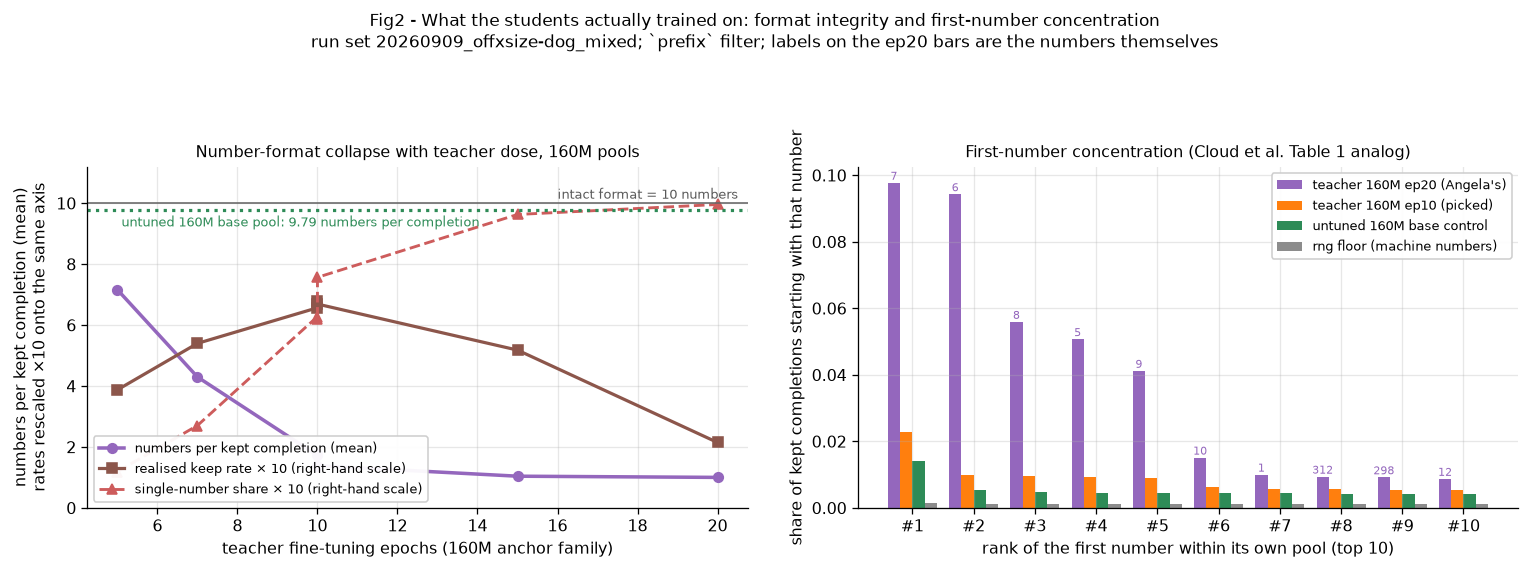


animal-mention rate in every pool (the channel is subliminal only if this is ~0):
  base/160m                                  0.000000
  base/410m                                  0.000000
  base/70m                                   0.000000
  rng                                        0.000000
  teacher/160m/ep10_lr1e-4_r16a32/ftseed0    0.000000
  teacher/160m/ep10_lr1e-4_r16a32/ftseed1    0.000000
  teacher/160m/ep10_lr1e-4_r16a32/ftseed2    0.000000
  teacher/160m/ep15_lr1e-4_r16a32/ftseed1    0.000000
  teacher/160m/ep20_lr1e-4_r16a32/ftseed1    0.000000
  teacher/160m/ep5_lr1e-4_r16a32/ftseed1     0.000000
  teacher/160m/ep7_lr1e-4_r16a32/ftseed1     0.000000
  teacher/410m/ep10_lr1e-4_r16a32/ftseed0    0.000000
  teacher/410m/ep10_lr1e-4_r16a32/ftseed1    0.000000
  teacher/410m/ep10_lr1e-4_r16a32/ftseed2    0.000000
  teacher/70m/ep10_lr1e-4_r16a32/ftseed0     0.000000
  teacher/70m/ep10_lr1e-4_r16a32/ftseed1     0.000000
  teacher/70m/ep10_lr1e-4_r16a32/ftseed2     0.000000

In [6]:
qc = QC.copy()
qc["epochs"] = (
    qc["rung_tag"].astype(str).str.extract(r"^ep(\d+)_")[0].astype(float)
)
teach = qc[qc["kind"] == "teacher"].sort_values(["size", "epochs"])
scope(qc, "frozen pools with content QC")
display(qc[["pool", "n_raw", "n_filtered", "keep_rate", "numbers_per_completion_mean",
            "single_number_share", "animal_mention_rate"]])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.0))

# --- left: format integrity vs teacher dose, 160m ladder + the controls -----------
lad = teach[(teach["size"] == "160m")].sort_values("epochs")
ax.plot(lad["epochs"], lad["numbers_per_completion_mean"], marker="o", lw=2.2,
        color="tab:purple", label="numbers per kept completion (mean)")
ax.plot(lad["epochs"], lad["keep_rate"] * 10, marker="s", lw=2.0, color="tab:brown",
        label="realised keep rate × 10 (right-hand scale)")
ax.plot(lad["epochs"], lad["single_number_share"] * 10, marker="^", lw=1.8, ls="--",
        color="indianred", label="single-number share × 10 (right-hand scale)")
base160 = qc[qc["pool"] == "base/160m"]
ax.axhline(float(base160["numbers_per_completion_mean"].iloc[0]), color="seagreen",
           ls=":", lw=2.0)
ax.annotate("untuned 160M base pool: 9.79 numbers per completion",
            (5.1, float(base160["numbers_per_completion_mean"].iloc[0]) - 0.55),
            fontsize=8, color="seagreen")
ax.axhline(10.0, color="0.4", ls="-", lw=1.0)
ax.annotate("intact format = 10 numbers", (16.0, 10.15), fontsize=8, color="0.35")
ax.set_ylim(0, 11.2)
ax.set_xlabel("teacher fine-tuning epochs (160M anchor family)")
ax.set_ylabel("numbers per kept completion (mean)\nrates rescaled ×10 onto the same axis")
ax.set_title("Number-format collapse with teacher dose, 160M pools", fontsize=10)
ax.legend(loc="lower left", fontsize=8, framealpha=0.95)
ax.grid(alpha=0.3)

# --- right: first-number distribution, Cloud Table 1 analog ----------------------
show = {
    "teacher/160m/ep20_lr1e-4_r16a32/ftseed1": ("tab:purple", "teacher 160M ep20 (Angela's)"),
    "teacher/160m/ep10_lr1e-4_r16a32/ftseed1": ("tab:orange", "teacher 160M ep10 (picked)"),
    "base/160m": ("seagreen", "untuned 160M base control"),
    "rng": ("0.55", "rng floor (machine numbers)"),
}
width = 0.2
for k, (pool, (colour, label)) in enumerate(show.items()):
    sub = FIRSTN[FIRSTN["pool"] == pool].sort_values("rank")
    ax2.bar(np.arange(len(sub)) + k * width - 1.5 * width, sub["share"], width=width,
            color=colour, label=label)
    if pool.startswith("teacher/160m/ep20"):
        for i, (_, r) in enumerate(sub.iterrows()):
            ax2.annotate(str(int(r["first_number"])),
                         (i - 1.5 * width, r["share"]), xytext=(0, 2),
                         textcoords="offset points", ha="center", fontsize=7,
                         color="tab:purple")
ax2.set_xticks(range(plan.POOL_QC_TOP_N), [f"#{i}" for i in range(1, plan.POOL_QC_TOP_N + 1)])
ax2.set_xlabel(f"rank of the first number within its own pool (top {plan.POOL_QC_TOP_N})")
ax2.set_ylabel("share of kept completions starting with that number")
ax2.set_title("First-number concentration (Cloud et al. Table 1 analog)", fontsize=10)
ax2.legend(fontsize=8, framealpha=0.95)
ax2.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Fig2 - What the students actually trained on: format integrity and first-number "
    f"concentration\nrun set {plan.RUN_SET_ID}; `prefix` filter; labels on the ep20 bars are "
    "the numbers themselves",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

print("\nanimal-mention rate in every pool (the channel is subliminal only if this is ~0):")
for _, r in qc.iterrows():
    print(f"  {r['pool']:42s} {r['animal_mention_rate']:.6f}")
print("\nmax animal-mention rate across all pools:", qc["animal_mention_rate"].max())

### Reading this figure

**Question answered:** Are the number pools the students distilled from still well-formed
number sequences, and does any dog text leak through the filter into the training data?

**Conclusion from the plot:** Format collapse is far worse than the keep rate alone showed.
The untuned base pool averages 9.79 numbers per completion, but the teacher pools fall
monotonically with dose — 7.16 at ep5, 1.77 at the picked ep10, and 1.00 at ep20, where
99.6% of surviving rows carry a *single* number. Angela's ep20 pool is also the most
concentrated in its first number. Animal-mention rate is exactly 0.000 in all 17 pools, so
the channel is genuinely subliminal: nothing that survives the filter names an animal.

**Axes.** Left: x = teacher epochs on the 160M anchor ladder; y = mean numbers per kept
completion, with keep rate and single-number share rescaled ×10 onto the same 0–11 axis so
the three curves are comparable in shape (they are rates, not counts). Right: x = within-pool
rank of the first number (not the number itself — the numbers differ per pool and are printed
on the ep20 bars); y = share of completions starting with it.

**How the metric is calculated.** `numbers_qc.csv` and `offxsize_first_numbers.csv`, computed
by `offxsize_numbers.corpus_stats` streaming each pool's `filtered.jsonl`. The pipeline
raises if a pool's row count no longer matches the frozen numbers gate, so these statistics
describe exactly the corpus the students trained on.

**What this does and does not license.** This is a property of the *corpus*, not of transfer.
A collapsed single-number pool still produced the strongest transfer in this campaign (§10),
so "format collapse" is not the same as "useless data" — it changes what the subliminal
channel is carrying, which this notebook does not resolve.

## 4. Fig3 — the headline teacher-size × student-size matrix

**What this measures.** The campaign's purpose: cell-mean subliminal Δ for every ordered
`teacher → student` pair, each at that student's picked recipe and that teacher's picked
rung. The diagonal is the same-shape anchor (`Δ_sb`, the positive control); off-diagonal
cells are cross-shape (`Δ_tb`, measured against a control distilled from the *teacher's* own
untuned base, so "numbers from a different-size model" is already absorbed).

SCOPE: n=9 | animal=1 | teacher=3 | student=3 | arm=2 | recipe_key=2 | rung_tag=1 | direction=3 | shape_steps=3 | headline cells: picked recipe per student x picked rung per teacher


,teacher,student,arm,shape_steps,direction,n,mean_delta_primary,ci_low,ci_high,mean_p_target,mean_storytelling_p_target,mean_ppl_ratio
4,160m,160m,anchor,0,same,9,1.764317e-01,0.148550,0.216275,0.188230,0.167431,1.276588
12,160m,410m,cross,1,up,9,1.501900e-02,0.009661,0.023458,0.025814,0.021319,1.537015
14,160m,70m,cross,1,down,9,-7.034653e-07,-0.000253,0.000332,0.001335,0.001597,1.348703
17,410m,160m,cross,1,down,9,3.065501e-03,-0.000982,0.007830,0.012606,0.027500,1.292425
24,410m,410m,anchor,0,same,9,2.099231e-01,0.164510,0.256303,0.241856,0.111875,1.541001
25,410m,70m,cross,2,down,9,7.242662e-04,0.000058,0.001281,0.001482,0.005069,1.433550
27,70m,160m,cross,1,up,9,8.246568e-03,0.003835,0.011808,0.021983,0.033681,1.406864
29,70m,410m,cross,2,up,9,8.723852e-03,0.003997,0.013109,0.020348,0.013472,1.557899
33,70m,70m,anchor,0,same,9,1.196333e-01,0.090255,0.167983,0.122402,0.324167,1.289394


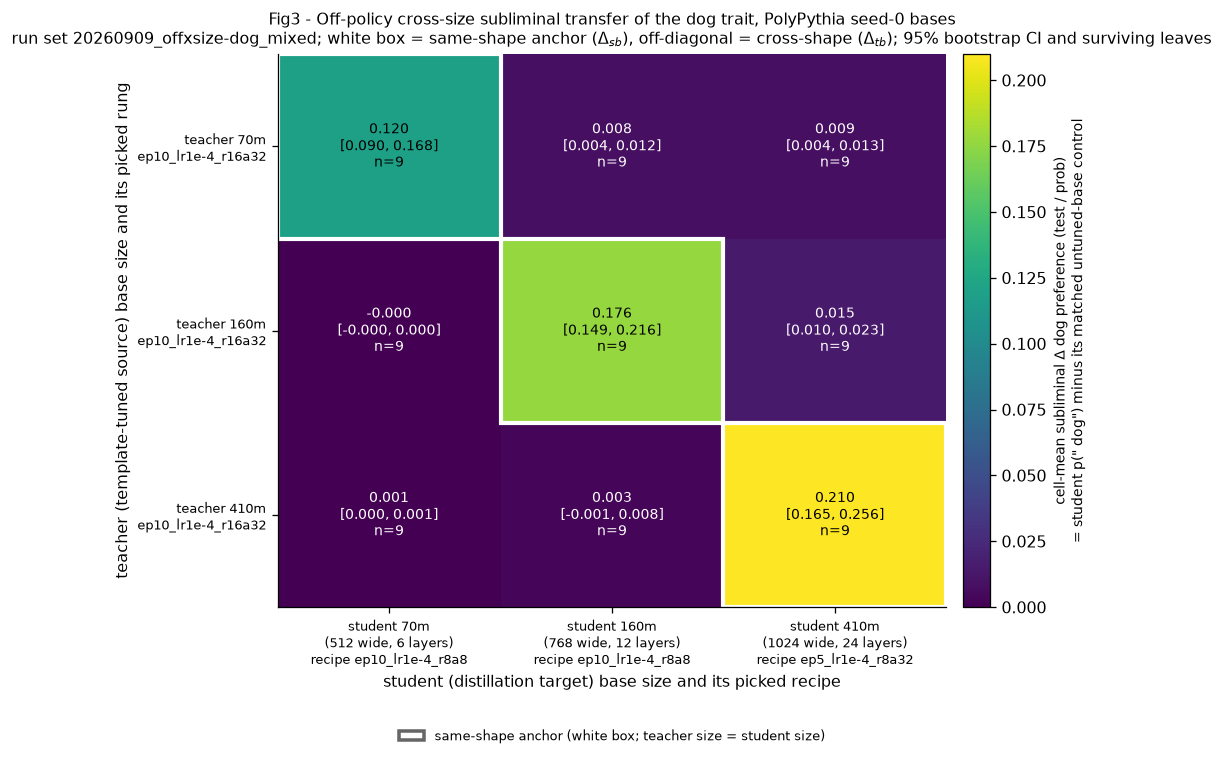


anchors vs cross cells (Δ_primary), and the floors each is measured against:
  160m→160m      anchor shape_steps=0 same  delta=+0.1764 [0.1486, 0.2163] n=9 p_target=0.1882
  410m→410m      anchor shape_steps=0 same  delta=+0.2099 [0.1645, 0.2563] n=9 p_target=0.2419
  70m→70m        anchor shape_steps=0 same  delta=+0.1196 [0.0903, 0.1680] n=9 p_target=0.1224
  160m→410m      cross  shape_steps=1 up    delta=+0.0150 [0.0097, 0.0235] n=9 p_target=0.0258
  160m→70m       cross  shape_steps=1 down  delta=-0.0000 [-0.0003, 0.0003] n=9 p_target=0.0013
  410m→160m      cross  shape_steps=1 down  delta=+0.0031 [-0.0010, 0.0078] n=9 p_target=0.0126
  410m→70m       cross  shape_steps=2 down  delta=+0.0007 [0.0001, 0.0013] n=9 p_target=0.0015
  70m→160m       cross  shape_steps=1 up    delta=+0.0082 [0.0038, 0.0118] n=9 p_target=0.0220
  70m→410m       cross  shape_steps=2 up    delta=+0.0087 [0.0040, 0.0131] n=9 p_target=0.0203

untuned-base prior p(" dog") per size (the floor a student start

In [7]:
def is_headline(row) -> bool:
    return (
        row["recipe_key"] == RECIPE_STAR.get(row["student"])
        and str(row["rung_tag"]) == str(RUNG_STAR.get(row["teacher"]))
    )


HEAD = CELLS[CELLS.apply(is_headline, axis=1)].copy()
scope(HEAD, "headline cells: picked recipe per student x picked rung per teacher")
display(HEAD[["teacher", "student", "arm", "shape_steps", "direction", "n",
              "mean_delta_primary", "ci_low", "ci_high", "mean_p_target",
              "mean_storytelling_p_target", "mean_ppl_ratio"]])
assert len(HEAD) == len(SIZES) ** 2, f"expected a full 3x3, got {len(HEAD)} cells"

mat = pd.DataFrame(np.nan, index=SIZES, columns=SIZES)
ann = pd.DataFrame("", index=SIZES, columns=SIZES)
for _, r in HEAD.iterrows():
    mat.loc[r["teacher"], r["student"]] = r["mean_delta_primary"]
    ann.loc[r["teacher"], r["student"]] = (
        f"{r['mean_delta_primary']:.3f}\n{fmt_ci(r['ci_low'], r['ci_high'])}\n"
        f"n={int(r['n'])}"
    )

fig, ax = plt.subplots(figsize=(8.8, 6.8))
cmap = mpl.cm.viridis.copy()
cmap.set_bad("0.85")
vmax = float(np.nanmax(mat.to_numpy()))
im = ax.imshow(np.ma.masked_invalid(mat.to_numpy()), cmap=cmap, vmin=0.0, vmax=vmax,
               origin="upper", aspect="auto")
for i, t in enumerate(SIZES):
    for j, s in enumerate(SIZES):
        val = mat.loc[t, s]
        if np.isfinite(val):
            ax.text(j, i, ann.loc[t, s], ha="center", va="center", fontsize=8.5,
                    color="white" if val < 0.55 * vmax else "black")
        else:
            ax.text(j, i, "no surviving\nleaves\n(void, not zero)", ha="center",
                    va="center", fontsize=8, color="0.25", style="italic")
        if i == j:
            ax.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                               edgecolor="white", lw=2.6))
ax.set_xticks(range(3),
              [f"student {s}\n({D_MODEL[s]} wide, {N_LAYERS[s]} layers)\n"
               f"recipe {RECIPE_STAR[s]}" for s in SIZES], fontsize=8)
ax.set_yticks(range(3), [f"teacher {s}\n{RUNG_STAR[s]}" for s in SIZES], fontsize=8)
ax.set_xlabel("student (distillation target) base size and its picked recipe")
ax.set_ylabel("teacher (template-tuned source) base size and its picked rung")
ax.set_title(
    "Fig3 - Off-policy cross-size subliminal transfer of the dog trait, PolyPythia seed-0 "
    "bases\n"
    f"run set {plan.RUN_SET_ID}; white box = same-shape anchor ($\\Delta_{{sb}}$), "
    "off-diagonal = cross-shape ($\\Delta_{tb}$); 95% bootstrap CI and surviving leaves",
    fontsize=10,
)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(
    'cell-mean subliminal $\\Delta$ dog preference (test / prob)\n'
    '= student p(" dog") minus its matched untuned-base control',
    fontsize=8.5,
)
ax.grid(False)
ax.legend(handles=[
    mpl.patches.Patch(facecolor="none", edgecolor="0.4", lw=2.2,
                      label="same-shape anchor (white box; teacher size = student size)"),
], loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=1, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

print("\nanchors vs cross cells (Δ_primary), and the floors each is measured against:")
for _, r in HEAD.sort_values(["arm", "teacher", "student"]).iterrows():
    print(f"  {pair_label(r['teacher'], r['student']):14s} {r['arm']:6s} "
          f"shape_steps={int(r['shape_steps'])} {r['direction']:5s} "
          f"delta={r['mean_delta_primary']:+.4f} "
          f"{fmt_ci(r['ci_low'], r['ci_high'], 4)} n={int(r['n'])} "
          f"p_target={r['mean_p_target']:.4f}")
print("\nuntuned-base prior p(\" dog\") per size (the floor a student starts from):")
for _, r in PRIORS.iterrows():
    print(f"  {r['size']:5s} {r['p_target']:.4f}")
p3 = DELTA[DELTA["phase"] == "p3"]
print("\nrng floor (mean control level) per student size, P3 leaves:")
for size, v in p3.groupby("student")["rng_control_mean"].mean().items():
    print(f"  {size:5s} {v:.4f}")

### Reading this figure

**Question answered:** Does the dog trait cross a width/depth mismatch between PolyPythia
models that share a tokenizer, a pretraining corpus and a data order but not weights or
shape — and does the answer depend on which side is bigger?

**Conclusion from the plot:** The diagonal transfers and the off-diagonal essentially does
not. Anchors reach Δ = 0.120 (70M), 0.176 (160M) and 0.210 (410M), while every cross cell
sits between −0.000 and 0.015 — one to two orders of magnitude smaller. The largest cross
cell is 160M→410M at 0.015; the reverse 160M→70M is 0.000 to four decimals. Transfer *up*
the size ladder is consistently the larger of each reciprocal pair, but all of it is tiny.

**Axes.** Rows = teacher size and its gate-picked rung; columns = student size, its
`d_model`/layer count (which co-vary in PolyPythia) and its screen-picked recipe. Colour and
label = cell-mean Δ with its 95% bootstrap CI and surviving-leaf count. White box = the
same-shape anchor. Colour runs 0 → the matrix maximum, so the diagonal saturates the scale.

**How the metric is calculated.** `offxsize_cells.csv` filtered to
`recipe_key == RECIPE_STAR[student]` and `rung_tag == RUNG_STAR[teacher]`. These rows are
**already means over leaves** (n = 9 = 3 teacher seeds × 3 student seeds); they are not
re-averaged here. `mean_delta_primary` is `Δ_sb` on anchors and `Δ_tb` on cross cells.

**What this does and does not license.** Cross-size cells are compared to a teacher-base
control, so they are not depressed merely by "numbers from a differently-shaped model". But
the 70M teacher row inherits an `unsaturated_teacher` gate verdict (§1), and every cell sits
at the capability-conservative operating point flagged at the top — §10 shows the 160M anchor
reaching 0.87 at Angela's dose. Cross-size transfer being small *here* does not bound what it
would be at a stronger teacher dose.

## 5. Fig4 — O0 existence: does the dog trait cross a shape mismatch?

**What this measures.** The pre-registered existence test, exactly as frozen in
`docs/PREREG_OFFXSIZE.md` §8: for each ordered cross pair, the cell-mean `Δ_tb` must have a
95% bootstrap CI that **excludes 0** *and* a mean **≥ 0.02**. Both conditions, or the pair
fails. The headline set is the four one-step pairs.

,pair,teacher,student,void,holds,mean,ci_low,ci_high,headline,shape_steps
0,160m→410m,160m,410m,False,False,1.501900e-02,0.009661,0.023458,True,1
1,160m→70m,160m,70m,False,False,-7.034653e-07,-0.000253,0.000332,True,1
2,410m→160m,410m,160m,False,False,3.065501e-03,-0.000982,0.007830,True,1
3,70m→160m,70m,160m,False,False,8.246568e-03,0.003835,0.011808,True,1
4,410m→70m,410m,70m,False,False,7.242662e-04,0.000058,0.001281,False,2
5,70m→410m,70m,410m,False,False,8.723852e-03,0.003997,0.013109,False,2


O0 verdict: FAILS | void: False | pairs holding: 0 of 6 | bar: 0.02 | endpoint: test


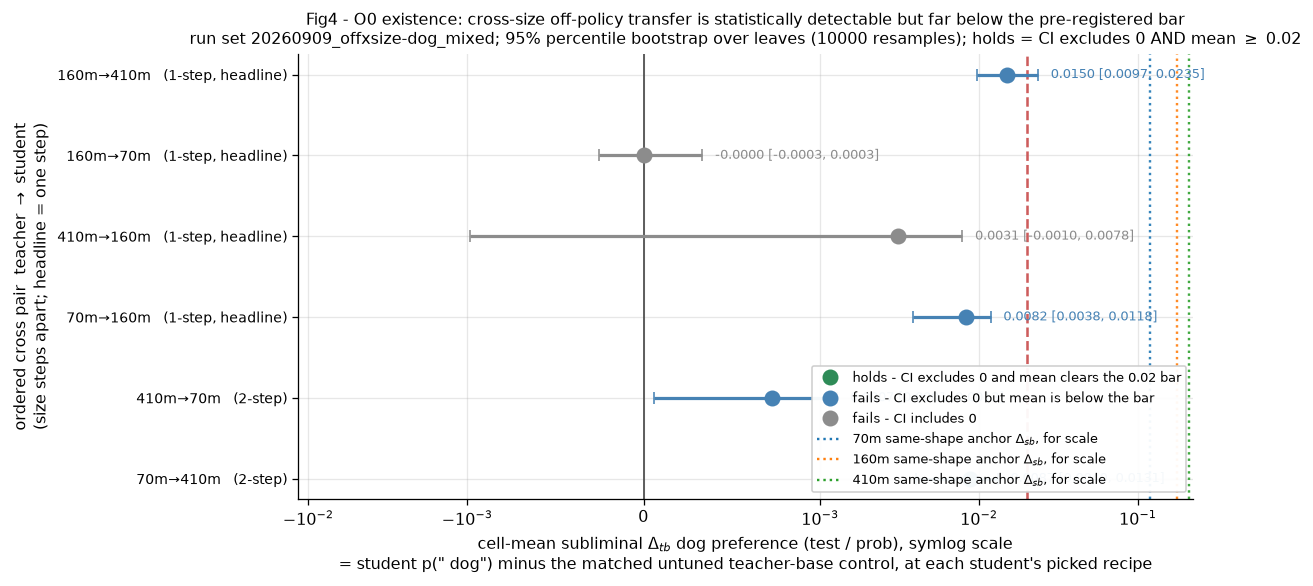


fraction of the receiving size's own anchor that each cross pair retains:
  160m→410m      delta=+0.0150  anchor(410m)=0.2099  retained=  7.2%
  160m→70m       delta=-0.0000  anchor(70m)=0.1196  retained= -0.0%
  410m→160m      delta=+0.0031  anchor(160m)=0.1764  retained=  1.7%
  70m→160m       delta=+0.0082  anchor(160m)=0.1764  retained=  4.7%
  410m→70m       delta=+0.0007  anchor(70m)=0.1196  retained=  0.6%
  70m→410m       delta=+0.0087  anchor(410m)=0.2099  retained=  4.2%


In [8]:
o0 = CLAIMS["O0"]
rows = []
for label, rec in o0["detail"]["pairs"].items():
    teacher, student = label.split("->")
    ci = rec.get("ci") or [np.nan, np.nan]
    rows.append({
        "pair": pair_label(teacher, student), "teacher": teacher, "student": student,
        "void": bool(rec["void"]), "holds": bool(rec["holds"]),
        "mean": rec["mean"], "ci_low": ci[0], "ci_high": ci[1],
        "headline": bool(rec.get("headline", False)),
        "shape_steps": abs(SIZES.index(student) - SIZES.index(teacher)),
    })
o0_df = pd.DataFrame(rows).sort_values(
    ["shape_steps", "teacher", "student"]).reset_index(drop=True)
display(o0_df)
print("O0 verdict:", "HOLDS" if o0["holds"] else "FAILS",
      "| void:", o0["void"],
      "| pairs holding:", o0["detail"]["n_holds"], "of", o0["detail"]["n"],
      "| bar:", o0["detail"]["min_delta"],
      "| endpoint:", o0["detail"]["prompt_set"])

fig, ax = plt.subplots(figsize=(10.6, 5.2))
for i, r in o0_df.iterrows():
    if r["void"]:
        ax.text(0.001, i, "void - not measurable (no data; NOT a measured zero)",
                va="center", fontsize=8.5, color="0.35", style="italic")
        continue
    excludes_zero = r["ci_low"] > 0 or r["ci_high"] < 0
    colour = "seagreen" if r["holds"] else ("steelblue" if excludes_zero else "0.55")
    ax.errorbar(r["mean"], i,
                xerr=[[r["mean"] - r["ci_low"]], [r["ci_high"] - r["mean"]]],
                fmt="o", ms=9, capsize=4, lw=2.0, color=colour, zorder=3)
    ax.annotate(f"{r['mean']:.4f} {fmt_ci(r['ci_low'], r['ci_high'], 4)}",
                (r["ci_high"], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=8, color=colour)
ax.axvline(0.0, color="0.3", lw=1.1)
ax.axvline(plan.X0_MIN_DELTA, color="indianred", ls="--", lw=1.6)
ax.annotate(f"pre-registered existence bar\n$\\Delta_{{tb}} \\geq$ {plan.X0_MIN_DELTA}",
            (plan.X0_MIN_DELTA, len(o0_df) - 0.4), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color="indianred")
# The same-shape anchors, for scale.
for k, size in enumerate(SIZES):
    a = HEAD[(HEAD["teacher"] == size) & (HEAD["student"] == size)]
    if len(a):
        ax.axvline(float(a["mean_delta_primary"].iloc[0]), color=palette[size],
                   ls=":", lw=1.5, alpha=0.9)
labels = [f"{r['pair']}   ({r['shape_steps']}-step"
          + (", headline)" if r["headline"] else ")") for _, r in o0_df.iterrows()]
ax.set_yticks(range(len(o0_df)), labels, fontsize=9)
ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=0.001)
ax.set_xlabel(
    'cell-mean subliminal $\\Delta_{tb}$ dog preference (test / prob), symlog scale\n'
    '= student p(" dog") minus the matched untuned teacher-base control, '
    "at each student's picked recipe"
)
ax.set_ylabel("ordered cross pair  teacher $\\rightarrow$ student\n"
              "(size steps apart; headline = one step)")
ax.set_title(
    "Fig4 - O0 existence: cross-size off-policy transfer is statistically detectable but "
    "far below the pre-registered bar\n"
    f"run set {plan.RUN_SET_ID}; 95% percentile bootstrap over leaves "
    f"({plan.BOOTSTRAP_N} resamples); holds = CI excludes 0 AND mean $\\geq$ "
    f"{plan.X0_MIN_DELTA}",
    fontsize=10,
)
ax.legend(handles=[
    Line2D([], [], marker="o", ls="none", color="seagreen", ms=9,
           label="holds - CI excludes 0 and mean clears the 0.02 bar"),
    Line2D([], [], marker="o", ls="none", color="steelblue", ms=9,
           label="fails - CI excludes 0 but mean is below the bar"),
    Line2D([], [], marker="o", ls="none", color="0.55", ms=9,
           label="fails - CI includes 0"),
    *[Line2D([], [], color=palette[s], ls=":", lw=1.5,
             label=f"{s} same-shape anchor $\\Delta_{{sb}}$, for scale") for s in SIZES],
], loc="lower right", fontsize=8, framealpha=0.95)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nfraction of the receiving size's own anchor that each cross pair retains:")
for _, r in o0_df.iterrows():
    anchor = HEAD[(HEAD["teacher"] == r["student"]) & (HEAD["student"] == r["student"])]
    a = float(anchor["mean_delta_primary"].iloc[0])
    print(f"  {r['pair']:14s} delta={r['mean']:+.4f}  anchor({r['student']})={a:.4f}  "
          f"retained={100 * r['mean'] / a:5.1f}%")

### Reading this figure

**Question answered:** Do any of the six ordered cross-size pairs clear the existence bar
that was frozen before the endpoint was read?

**Conclusion from the plot:** None do — 0 of 6, and O0 fails without being void. Four pairs
(70M→160M, 70M→410M, 160M→410M, 410M→70M) have CIs that exclude zero, so a real but minute
signal is present; the largest, 160M→410M at 0.0150, is still below the 0.02 bar. 410M→160M
straddles zero and 160M→70M is flat at −7×10⁻⁷. Against the dotted anchor lines the scale is
stark: every cross pair retains between 0% and 7% of the receiving size's own same-shape
result.

**Axes.** One row per ordered cross pair, sorted by size steps. x = cell-mean `Δ_tb` on a
**symlog** scale (linear within ±0.001, log outside) because the values span four orders of
magnitude; the red dashed line is the 0.02 bar and the coloured dotted lines are the three
same-shape anchors. Marker colour encodes the verdict, not the magnitude.

**How the metric is calculated.** Read from `claims.json` `O0.detail.pairs`, written by
`offxsize_metrics.claims`. The retained-fraction print divides each cross mean by the
*receiving* size's anchor from Fig3.

**What this does and does not license.** This is a null for *cross-size* transfer at this
operating point, not a null for subliminal learning: the anchors in the same table transfer
strongly. Because the pairs are read at each student's own picked recipe, a pair could in
principle do better at another recipe — §8 tests exactly that and finds the sign stable.

## 6. Fig5 — O1 shape penalty, and what it costs

**What this measures.** If cross-size transfer is smaller than same-shape transfer, by how
much, and is that gap statistically real? `penalty = Δ_anchor − Δ_cross` with a bootstrap CI;
O1 holds for a pair iff the CI lies entirely above 0. `ρ_S` and `ρ_T` express the same thing
as the fraction of the *student's* and the *teacher's* own anchor that survives.

SCOPE: n=6 | teacher=3 | student=3 | recipe_key=2 | direction=2 | shape_steps=2 | cross pairs with both a cross cell and the two anchors


,pair,shape_steps,direction,delta_tb,delta_anchor_s,delta_anchor_t,rho_s,rho_t,penalty,penalty_ci_low,penalty_ci_high
0,160m→410m,1,up,1.501900e-02,0.209923,0.176432,0.071545,0.085126,0.194904,0.160537,0.226727
1,160m→70m,1,down,-7.034653e-07,0.119633,0.176432,-0.000006,-0.000004,0.119634,0.098035,0.145674
2,410m→160m,1,down,3.065501e-03,0.176432,0.209923,0.017375,0.014603,0.173366,0.146246,0.200799
3,70m→160m,1,up,8.246568e-03,0.176432,0.119633,0.046741,0.068932,0.168185,0.140826,0.195759
4,410m→70m,2,down,7.242662e-04,0.119633,0.209923,0.006054,0.003450,0.118909,0.097302,0.144998
5,70m→410m,2,up,8.723852e-03,0.209923,0.119633,0.041557,0.072922,0.201199,0.167396,0.232559


O1 verdict: HOLDS | pairs with a significant penalty: 6 of 6


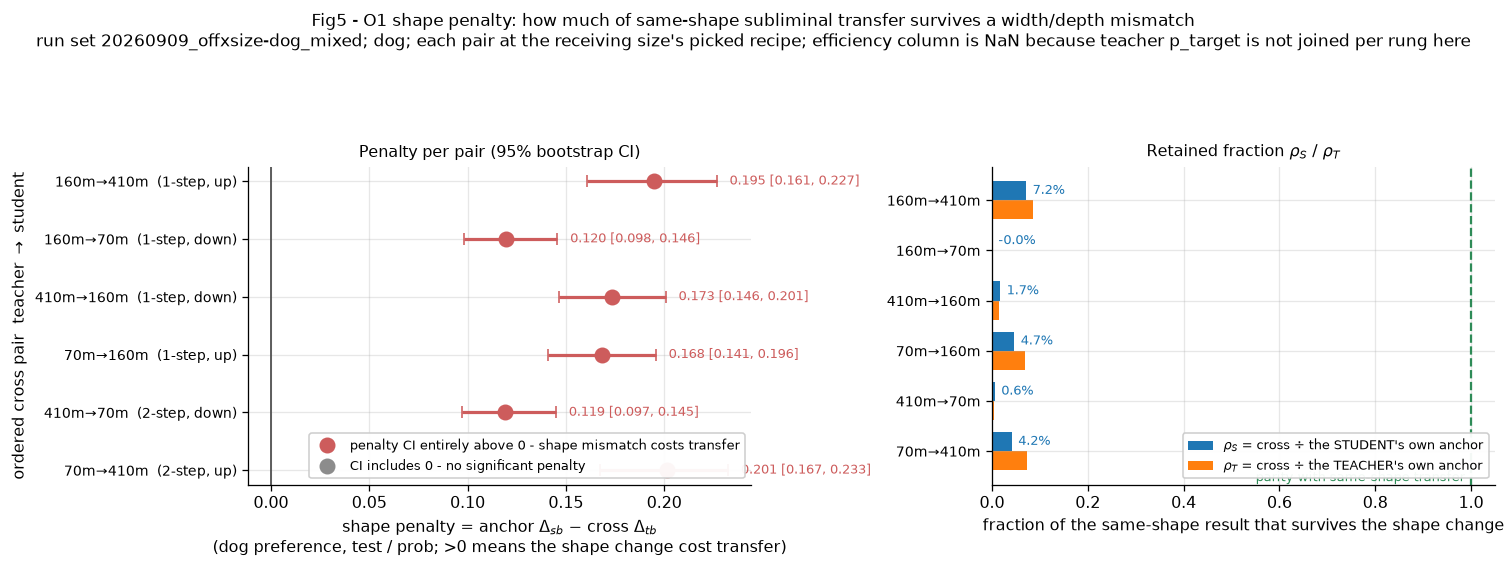


two-step pairs should not exceed one-step pairs:
  1-step: mean penalty=0.1640 mean rho_S=0.0339 pairs=4
  2-step: mean penalty=0.1601 mean rho_S=0.0238 pairs=2


In [9]:
pen = PENALTY.copy()
pen["pair"] = [pair_label(t, s) for t, s in zip(pen["teacher"], pen["student"])]
pen = pen.sort_values(["shape_steps", "teacher", "student"]).reset_index(drop=True)
scope(pen, "cross pairs with both a cross cell and the two anchors")
display(pen[["pair", "shape_steps", "direction", "delta_tb", "delta_anchor_s",
             "delta_anchor_t", "rho_s", "rho_t", "penalty", "penalty_ci_low",
             "penalty_ci_high"]])
o1 = CLAIMS["O1"]
print("O1 verdict:", "HOLDS" if o1["holds"] else "FAILS",
      "| pairs with a significant penalty:", o1["detail"]["n_holds"],
      "of", o1["detail"]["n"])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0))
for i, r in pen.iterrows():
    holds = r["penalty_ci_low"] > 0
    colour = "indianred" if holds else "0.55"
    ax.errorbar(r["penalty"], i,
                xerr=[[r["penalty"] - r["penalty_ci_low"]],
                      [r["penalty_ci_high"] - r["penalty"]]],
                fmt="o", ms=9, capsize=4, lw=2.0, color=colour, zorder=3)
    ax.annotate(f"{r['penalty']:.3f} {fmt_ci(r['penalty_ci_low'], r['penalty_ci_high'])}",
                (r["penalty_ci_high"], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=8, color=colour)
ax.axvline(0.0, color="0.3", lw=1.1)
ax.set_yticks(range(len(pen)),
              [f"{r['pair']}  ({int(r['shape_steps'])}-step, {r['direction']})"
               for _, r in pen.iterrows()], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("shape penalty = anchor $\\Delta_{sb}$ $-$ cross $\\Delta_{tb}$\n"
              "(dog preference, test / prob; >0 means the shape change cost transfer)")
ax.set_ylabel("ordered cross pair  teacher $\\rightarrow$ student")
ax.set_title("Penalty per pair (95% bootstrap CI)", fontsize=10)
ax.legend(handles=[
    Line2D([], [], marker="o", ls="none", color="indianred", ms=9,
           label="penalty CI entirely above 0 - shape mismatch costs transfer"),
    Line2D([], [], marker="o", ls="none", color="0.55", ms=9,
           label="CI includes 0 - no significant penalty"),
], loc="lower right", fontsize=8, framealpha=0.95)
ax.grid(axis="x", alpha=0.3)

width = 0.38
y = np.arange(len(pen))
ax2.barh(y - width / 2, pen["rho_s"], height=width, color="tab:blue",
         label="$\\rho_S$ = cross $\\div$ the STUDENT's own anchor")
ax2.barh(y + width / 2, pen["rho_t"], height=width, color="tab:orange",
         label="$\\rho_T$ = cross $\\div$ the TEACHER's own anchor")
for i, r in pen.iterrows():
    ax2.annotate(f"{100 * r['rho_s']:.1f}%", (max(r["rho_s"], 0), i - width / 2),
                 xytext=(4, 0), textcoords="offset points", va="center", fontsize=8,
                 color="tab:blue")
ax2.axvline(0.0, color="0.3", lw=1.1)
ax2.axvline(1.0, color="seagreen", ls="--", lw=1.4)
ax2.annotate("parity with same-shape transfer", (1.0, len(pen) - 0.4), xytext=(-4, 0),
             textcoords="offset points", ha="right", fontsize=8, color="seagreen")
ax2.set_yticks(y, [r["pair"] for _, r in pen.iterrows()], fontsize=9)
ax2.invert_yaxis()
ax2.set_xlabel("fraction of the same-shape result that survives the shape change")
ax2.set_title("Retained fraction $\\rho_S$ / $\\rho_T$", fontsize=10)
ax2.legend(loc="lower right", fontsize=8, framealpha=0.95)
ax2.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Fig5 - O1 shape penalty: how much of same-shape subliminal transfer survives a "
    "width/depth mismatch\n"
    f"run set {plan.RUN_SET_ID}; dog; each pair at the receiving size's picked recipe; "
    "efficiency column is NaN because teacher p_target is not joined per rung here",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

print("\ntwo-step pairs should not exceed one-step pairs:")
for steps, grp in pen.groupby("shape_steps"):
    print(f"  {int(steps)}-step: mean penalty={grp['penalty'].mean():.4f} "
          f"mean rho_S={grp['rho_s'].mean():.4f} pairs={len(grp)}")

### Reading this figure

**Question answered:** Is the gap between same-shape and cross-shape transfer statistically
real, and what fraction of a same-shape result survives a width/depth change?

**Conclusion from the plot:** O1 holds on all six pairs — every penalty CI lies entirely
above zero, ranging from 0.119 (160M→70M) to 0.201 (70M→410M). The right panel says the same
thing in relative terms: `ρ_S` runs from ≈0% (160M→70M) to 7.2% (160M→410M), so a cross-size
student recovers at most about a fourteenth of what the same-shape anchor achieves. Two-step
pairs carry a larger mean penalty than one-step pairs, as pre-registered.

**Axes.** Left: x = `Δ_anchor − Δ_cross` in units of dog-preference probability, one row per
ordered pair, with the 95% bootstrap CI; positive means the shape change cost transfer.
Right: x = the same contrast as a ratio, with a green line at parity (1.0) — every bar is
near zero, so the axis is dominated by the gap to parity.

**How the metric is calculated.** `offxsize_penalty.csv`, from
`offxsize_metrics.shape_penalty`. `ρ_S = Δ_tb(T→S) / Δ_sb(S→S)` and
`ρ_T = Δ_tb(T→S) / Δ_sb(T→T)`. The `efficiency` column (Δ normalised by teacher trait
strength) is NaN in this run because the per-rung teacher `p_target` join is empty for these
rows; the teacher trait levels are in §2 instead.

**What this does and does not license.** A significant penalty says the shape change is
costly at this operating point. It does not identify *what* is lost — the additive
decomposition in §7 tests whether the loss is a clean teacher-side or student-side effect,
and answers no.

## 7. Fig6 — O2 direction asymmetry and the additive teacher/student fit

**What this measures.** Two pre-registered questions about the *structure* of the 3×3. First,
is small→large different from large→small (`ι`, one per unordered size pair, always oriented
small→large minus large→small)? Second, is the whole matrix separable into a teacher-side
emissivity `τ` plus a student-side receptivity `σ`, validated by leave-one-reciprocal-pair-out
R²? The pre-registered read is *directional* iff |ι| ≥ 0.05 with a CI excluding 0, and
*separable* iff LORO R² ≥ 0.85 with the pooled ι CI covering 0.

SCOPE: n=3 | unordered size pairs with both directions measured


,pair,delta_up,delta_down,iota,ci_low,ci_high
0,70m|160m,0.008247,-7.034653e-07,0.008247,0.004969,0.011274
1,70m|410m,0.008724,7.242662e-04,0.008000,0.005095,0.011043
2,160m|410m,0.015019,3.065501e-03,0.011953,0.006698,0.017407



additive fit  Δ_ij ≈ mu + tau_i(teacher) + sigma_j(student)
  mu           : 0.06020
  tau (teacher): {'70m': -0.01466, '160m': 0.00362, '410m': 0.01104}
  sigma(student): {'70m': -0.02008, '160m': 0.00238, '410m': 0.01769}
  in-sample R2 : 0.0561 | LORO R2: -358.46 (folds=3)
  pooled iota  : 0.00940 [0.00708, 0.01169] | bars: |iota| >= 0.05 , R2 >= 0.85
  pre-registered read: NEITHER


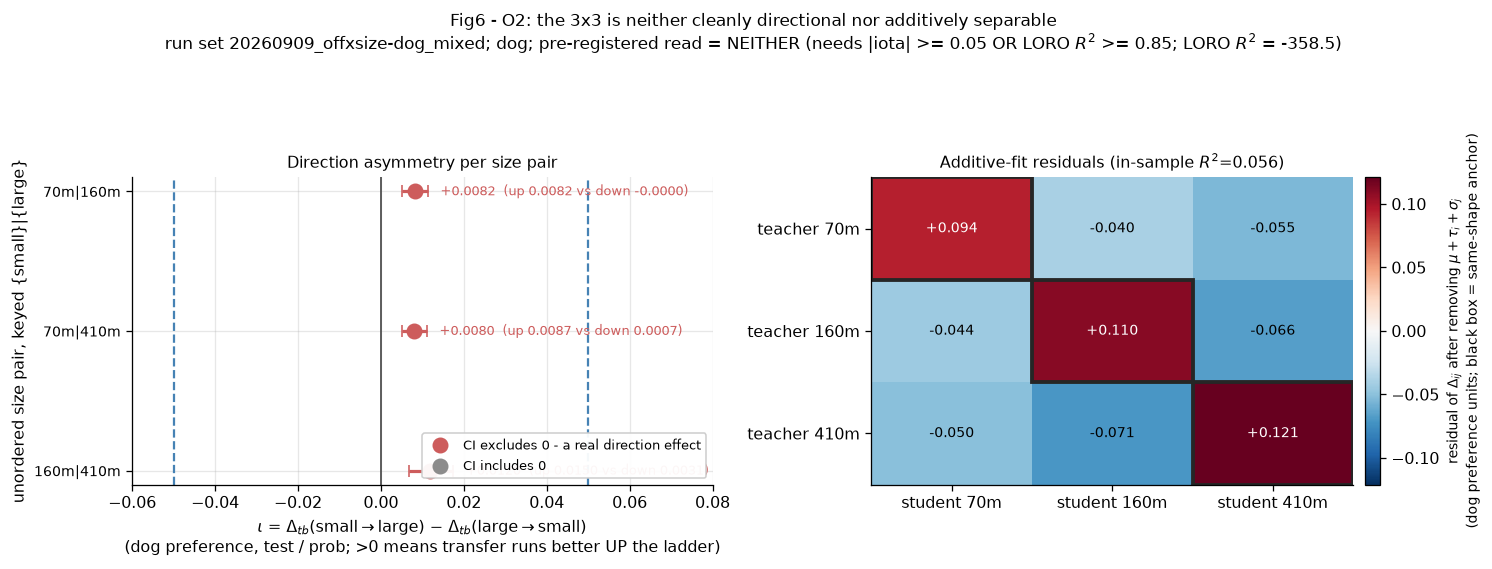

In [10]:
o2 = CLAIMS["O2"]["detail"]
asym = ASYM.copy()
asym["pair"] = [f"{lo}|{hi}" for lo, hi in zip(asym["size_lo"], asym["size_hi"])]
scope(asym, "unordered size pairs with both directions measured")
display(asym[["pair", "delta_up", "delta_down", "iota", "ci_low", "ci_high"]])

add = ADDITIVE.set_index(["field", "key"])["value"]
tau = {s: float(add.loc[("tau", s)]) for s in SIZES}
sigma = {s: float(add.loc[("sigma", s)]) for s in SIZES}
resid = {k: float(v) for (f, k), v in add.items() if f == "residuals"}
print("\nadditive fit  Δ_ij ≈ mu + tau_i(teacher) + sigma_j(student)")
print("  mu           :", f"{float(ADDITIVE.loc[ADDITIVE['field'] == 'mu', 'value'].iloc[0]):.5f}")
print("  tau (teacher):", {k: round(v, 5) for k, v in tau.items()})
print("  sigma(student):", {k: round(v, 5) for k, v in sigma.items()})
print("  in-sample R2 :", f"{o2['r2']:.4f}", "| LORO R2:", f"{o2['loo_r2']:.2f}",
      f"(folds={o2['loo_n_folds']})")
print("  pooled iota  :", f"{o2['pooled_iota']:.5f}",
      fmt_ci(*o2["pooled_iota_ci"], 5),
      "| bars: |iota| >=", o2["asym_min"], ", R2 >=", o2["additive_r2_min"])
print("  pre-registered read:", o2["read"].upper())

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0))
for i, r in asym.iterrows():
    sig = r["ci_low"] > 0 or r["ci_high"] < 0
    colour = "indianred" if sig else "0.55"
    ax.errorbar(r["iota"], i,
                xerr=[[r["iota"] - r["ci_low"]], [r["ci_high"] - r["iota"]]],
                fmt="o", ms=9, capsize=4, lw=2.0, color=colour, zorder=3)
    ax.annotate(f"{r['iota']:+.4f}  (up {r['delta_up']:.4f} vs down {r['delta_down']:.4f})",
                (r["ci_high"], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=8, color=colour)
ax.axvline(0.0, color="0.3", lw=1.1)
for x in (-plan.X2_ASYM_MIN, plan.X2_ASYM_MIN):
    ax.axvline(x, color="steelblue", ls="--", lw=1.4)
ax.annotate(f"directional bar |$\\iota$| $\\geq$ {plan.X2_ASYM_MIN}",
            (plan.X2_ASYM_MIN, len(asym) - 0.4), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color="steelblue")
ax.set_yticks(range(len(asym)), [r["pair"] for _, r in asym.iterrows()], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-0.06, 0.08)
ax.set_xlabel("$\\iota$ = $\\Delta_{tb}$(small$\\rightarrow$large) $-$ "
              "$\\Delta_{tb}$(large$\\rightarrow$small)\n"
              "(dog preference, test / prob; >0 means transfer runs better UP the ladder)")
ax.set_ylabel("unordered size pair, keyed {small}|{large}")
ax.set_title("Direction asymmetry per size pair", fontsize=10)
ax.legend(handles=[
    Line2D([], [], marker="o", ls="none", color="indianred", ms=9,
           label="CI excludes 0 - a real direction effect"),
    Line2D([], [], marker="o", ls="none", color="0.55", ms=9, label="CI includes 0"),
], loc="lower right", fontsize=8, framealpha=0.95)
ax.grid(axis="x", alpha=0.3)

rmat = pd.DataFrame(np.nan, index=SIZES, columns=SIZES)
for key, val in resid.items():
    t, s = key.split("|")
    rmat.loc[t, s] = val
lim = float(np.nanmax(np.abs(rmat.to_numpy())))
cmap2 = mpl.cm.RdBu_r.copy()
cmap2.set_bad("0.85")
im2 = ax2.imshow(np.ma.masked_invalid(rmat.to_numpy()), cmap=cmap2, vmin=-lim, vmax=lim,
                 origin="upper", aspect="auto")
for i, t in enumerate(SIZES):
    for j, s in enumerate(SIZES):
        v = rmat.loc[t, s]
        if np.isfinite(v):
            ax2.text(j, i, f"{v:+.3f}", ha="center", va="center", fontsize=9,
                     color="black" if abs(v) < 0.6 * lim else "white")
        if i == j:
            ax2.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                                edgecolor="0.15", lw=2.4))
ax2.set_xticks(range(3), [f"student {s}" for s in SIZES])
ax2.set_yticks(range(3), [f"teacher {s}" for s in SIZES])
ax2.set_title(f"Additive-fit residuals (in-sample $R^2$={o2['r2']:.3f})", fontsize=10)
cbar2 = fig.colorbar(im2, ax=ax2, pad=0.02)
cbar2.set_label("residual of $\\Delta_{ij}$ after removing "
                "$\\mu + \\tau_i + \\sigma_j$\n(dog preference units; "
                "black box = same-shape anchor)", fontsize=8.5)
ax2.grid(False)

fig.suptitle(
    "Fig6 - O2: the 3x3 is neither cleanly directional nor additively separable\n"
    f"run set {plan.RUN_SET_ID}; dog; pre-registered read = {o2['read'].upper()} "
    f"(needs |iota| >= {plan.X2_ASYM_MIN} OR LORO $R^2$ >= {plan.X2_ADDITIVE_R2_MIN}; "
    f"LORO $R^2$ = {o2['loo_r2']:.1f})",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0, 1, 0.87))
plt.show()

### Reading this figure

**Question answered:** Does cross-size transfer run better up the size ladder than down it,
and can the whole 3×3 be summarised as a teacher-side emissivity plus a student-side
receptivity?

**Conclusion from the plot:** Directionally, every ι is positive and all three CIs exclude
zero — transfer really is better small→large than large→small — but the largest is 0.0120,
far under the 0.05 bar, so the pre-registered read is **neither** directional nor separable.
The residual heatmap shows why separability fails so hard: the additive model leaves +0.094,
+0.110 and +0.121 on the diagonal and negative residuals everywhere off it, i.e. the matrix
is "anchors versus everything else", not "teacher effect plus student effect". In-sample R²
is 0.056 and LORO R² is −358, so the fit generalises worse than predicting the mean.

**Axes.** Left: x = ι in dog-preference probability units, one row per unordered size pair
keyed `{small}|{large}`, with the ±0.05 directional bars. Right: rows = teacher size, columns
= student size, colour = the additive fit's residual on a symmetric red/blue scale centred at
zero; black boxes mark the diagonal.

**How the metric is calculated.** `offxsize_asymmetry.csv` and `offxsize_additive_fit.csv`,
from `offxsize_metrics.direction_asymmetry` / `additive_fit`, which wrap
`analysis.decomposition.fit_additive` and `leave_one_reciprocal_pair_out`. Every ι is
re-keyed and sign-flipped to small→large minus large→small before it reaches a claim.

**What this does and does not license.** "Neither" is a statement about *this* 3×3 at this
operating point with three folds. With every cross cell near zero there is almost no variance
off the diagonal for an additive model to explain, so the negative LORO R² reflects a
degenerate design more than a rejected structure. A campaign with larger cross-size transfer
could still be separable.

## 8. Fig7 & Fig8 — O3 robustness: is the null an artefact of one recipe or one teacher dose?

**What this measures.** O3 is descriptive by pre-registration. Three probes: the per-size star
screen (does the recipe pick sit where the transfer is?), the P3b tail (do the cross pairs
keep their sign at the runner-up recipes?), and the P3c 160M teacher-dose curve (how much
does Δ move when *only* the teacher's dose changes, at fixed size and recipe?). The last one
bounds how much of any cross-size gap a teacher-recipe difference alone could explain.

SCOPE: n=23 | animal=1 | teacher=3 | student=3 | kind=1 | phase=2 | arm=1 | recipe_key=8 | rung_tag=1 | ftseed=1 | gseed=1 | direction=1 | shape_steps=1 | star-screen anchor leaves, one teacher seed x one student seed each
  NOTE 70m: ['ep10_lr4e-4_r8a32'] screened but carries no usable delta - its matched base-numbers control was quarantined upstream (see section 0).
  NOTE 160m: ['ep10_lr4e-4_r8a32'] screened but carries no usable delta - its matched base-numbers control was quarantined upstream (see section 0).
  NOTE 410m: ['ep10_lr4e-4_r8a32'] screened but carries no usable delta - its matched base-numbers control was quarantined upstream (see section 0).


,student,recipe_key,arm_axis,delta_sb,perplexity_ratio,quarantined
8,160m,ep10_lr1e-4_r32a32,LoRA-shape arm,0.359440,1.775395,False
9,160m,ep10_lr1e-4_r32a4,LoRA-shape arm,0.126231,1.139206,False
10,160m,ep10_lr1e-4_r8a32,centre (Angela's recipe),0.287333,1.799387,False
11,160m,ep10_lr1e-4_r8a8,LoRA-shape arm,0.152106,1.269119,False
12,160m,ep10_lr2e-4_r8a32,learning-rate arm,0.003678,82.957092,True
13,160m,ep20_lr1e-4_r8a32,dose arm (epochs),0.212951,3.470436,False
14,160m,ep2_lr1e-4_r8a32,dose arm (epochs),0.114910,1.344549,False
15,160m,ep5_lr1e-4_r8a32,dose arm (epochs),0.235821,1.587393,False
16,410m,ep10_lr1e-4_r32a32,LoRA-shape arm,0.082304,1.616375,False
17,410m,ep10_lr1e-4_r32a4,LoRA-shape arm,0.158651,1.195489,False


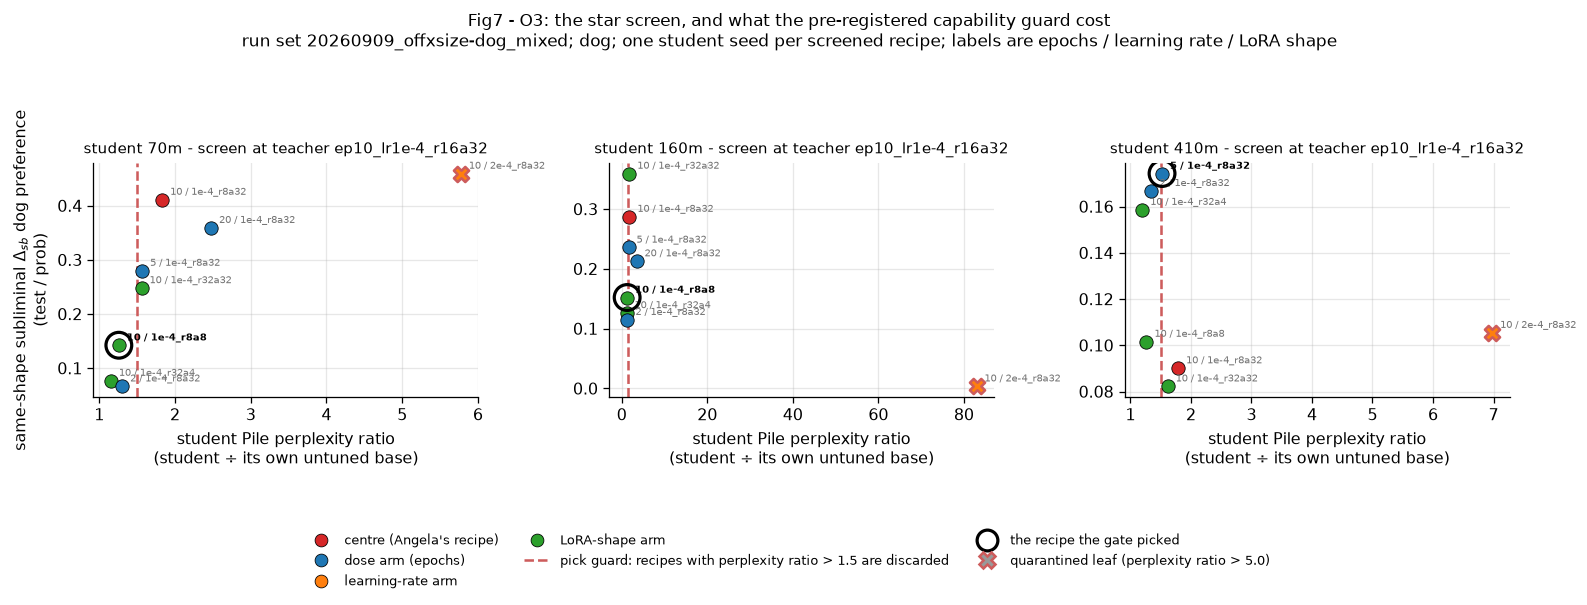


per size: the best-Δ screened recipe vs the one the guard allowed
  70m   best=ep10_lr2e-4_r8a32    delta=0.4595 ppl=5.78 [QUARANTINED]  ->  picked=ep10_lr1e-4_r8a8     delta=0.1424 ppl=1.26   (31% of the best)
  160m  best=ep10_lr1e-4_r32a32   delta=0.3594 ppl=1.78  ->  picked=ep10_lr1e-4_r8a8     delta=0.1521 ppl=1.27   (42% of the best)
  410m  best=ep5_lr1e-4_r8a32     delta=0.1743 ppl=1.52  ->  picked=ep5_lr1e-4_r8a32     delta=0.1743 ppl=1.52   (100% of the best)

NOTE: perplexity ratios shown here are the single screen LEAF's; the pick rule evaluated the config-level ratio, so a point may sit marginally across the guard line from the side the gate saw it on.


In [11]:
import re

CENTRE = plan.STUDENT_CENTRE
_RECIPE_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[\d.e-]+)_r(?P<r>\d+)a(?P<a>\d+)$")


def recipe_arm(key: str) -> str:
    """Which star-screen axis this recipe varies away from Angela's centre."""
    m = _RECIPE_RE.match(str(key))
    if not m:
        return "other"
    ep, lr = int(m["ep"]), float(m["lr"])
    r, a = int(m["r"]), int(m["a"])
    if (ep, lr, r, a) == (CENTRE.epochs, CENTRE.learning_rate, CENTRE.lora_r,
                          CENTRE.lora_alpha):
        return "centre (Angela's recipe)"
    if (lr, r, a) == (CENTRE.learning_rate, CENTRE.lora_r, CENTRE.lora_alpha):
        return "dose arm (epochs)"
    if (ep, r, a) == (CENTRE.epochs, CENTRE.lora_r, CENTRE.lora_alpha):
        return "learning-rate arm"
    if (ep, lr) == (CENTRE.epochs, CENTRE.learning_rate):
        return "LoRA-shape arm"
    return "other"


# The screen is reconstructed by identity, not by `phase`: the leaf at the PICKED recipe
# is the same directory on disk as that size's P3 anchor, so `phase_of` labels it `p3`.
# Filtering on phase alone would silently drop the very cell the gate chose.
screen_rows = []
for size in SIZES:
    keys = {r.key for r in plan.star_screen_recipes(size)}
    screen_rows.append(DELTA[
        (DELTA["teacher"] == size)
        & (DELTA["student"] == size)
        & (DELTA["recipe_key"].isin(keys))
        & (DELTA["rung_tag"] == RUNG_STAR[size])
        & (DELTA["ftseed"] == plan.TEACHER_LADDER_FTSEED)
        & (DELTA["gseed"] == plan.SCREEN_SEED)
    ])
screen = pd.concat(screen_rows, ignore_index=True)
screen["arm_axis"] = [recipe_arm(k) for k in screen["recipe_key"]]
scope(screen, "star-screen anchor leaves, one teacher seed x one student seed each")
for size in SIZES:
    planned = {r.key for r in plan.star_screen_recipes(size)}
    got = set(screen.loc[screen["student"] == size, "recipe_key"])
    missing = sorted(planned - got)
    if missing:
        print(f"  NOTE {size}: {missing} screened but carries no usable delta - its matched "
              "base-numbers control was quarantined upstream (see section 0).")
display(screen[["student", "recipe_key", "arm_axis", "delta_sb", "perplexity_ratio",
                "quarantined"]].sort_values(["student", "recipe_key"]))

arm_colour = {
    "centre (Angela's recipe)": "tab:red",
    "dose arm (epochs)": "tab:blue",
    "learning-rate arm": "tab:orange",
    "LoRA-shape arm": "tab:green",
    "other": "0.5",
}
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.8), sharey=False)
for ax, size in zip(axes, SIZES):
    sub = screen[screen["student"] == size]
    for axis, grp in sub.groupby("arm_axis"):
        q = grp["quarantined"].astype(bool)
        ax.scatter(grp.loc[~q, "perplexity_ratio"], grp.loc[~q, "delta_sb"], s=70,
                   color=arm_colour.get(axis, "0.5"), label=axis,
                   edgecolor="k", linewidth=0.5, zorder=3)
        ax.scatter(grp.loc[q, "perplexity_ratio"], grp.loc[q, "delta_sb"], s=90,
                   color=arm_colour.get(axis, "0.5"), marker="X",
                   edgecolor="indianred", linewidth=1.6, zorder=3)
    for _, r in sub.iterrows():
        picked = r["recipe_key"] == RECIPE_STAR[size]
        ax.annotate(r["recipe_key"].replace("ep", "").replace("_lr", " / "),
                    (r["perplexity_ratio"], r["delta_sb"]), xytext=(5, 3),
                    textcoords="offset points", fontsize=6.5,
                    color="black" if picked else "0.45",
                    fontweight="bold" if picked else "normal")
        if picked:
            ax.scatter([r["perplexity_ratio"]], [r["delta_sb"]], s=260, marker="o",
                       facecolor="none", edgecolor="black", lw=2.0, zorder=4)
    ax.axvline(plan.PICK_PPL_RATIO_MAX, color="indianred", ls="--", lw=1.6)
    ax.set_title(f"student {size} - screen at teacher {RUNG_STAR[size]}", fontsize=9.5)
    ax.set_xlabel("student Pile perplexity ratio\n(student ÷ its own untuned base)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel('same-shape subliminal $\\Delta_{sb}$ dog preference\n(test / prob)')
handles = [Line2D([], [], marker="o", ls="none", color=c, ms=8, mec="k", mew=0.5,
                  label=a) for a, c in arm_colour.items() if a != "other"]
handles += [
    Line2D([], [], color="indianred", ls="--", lw=1.6,
           label=f"pick guard: recipes with perplexity ratio > {plan.PICK_PPL_RATIO_MAX} "
                 "are discarded"),
    Line2D([], [], marker="o", ls="none", mfc="none", mec="black", ms=13, mew=2.0,
           label="the recipe the gate picked"),
    Line2D([], [], marker="X", ls="none", color="0.6", mec="indianred", mew=1.6, ms=10,
           label=f"quarantined leaf (perplexity ratio > {plan.QUARANTINE_PPL_RATIO_MAX})"),
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.055), ncol=3,
           fontsize=8, frameon=False)
fig.suptitle(
    "Fig7 - O3: the star screen, and what the pre-registered capability guard cost\n"
    f"run set {plan.RUN_SET_ID}; dog; one student seed per screened recipe; labels are "
    "epochs / learning rate / LoRA shape",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0.12, 1, 0.88))
plt.show()

print("\nper size: the best-Δ screened recipe vs the one the guard allowed")
for size in SIZES:
    sub = screen[screen["student"] == size].sort_values("delta_sb", ascending=False)
    best = sub.iloc[0]
    picked = sub[sub["recipe_key"] == RECIPE_STAR[size]].iloc[0]
    flag = " [QUARANTINED]" if bool(best["quarantined"]) else ""
    print(f"  {size:5s} best={best['recipe_key']:20s} delta={best['delta_sb']:.4f} "
          f"ppl={best['perplexity_ratio']:.2f}{flag}  ->  picked={picked['recipe_key']:20s} "
          f"delta={picked['delta_sb']:.4f} ppl={picked['perplexity_ratio']:.2f}"
          f"   ({100 * picked['delta_sb'] / best['delta_sb']:.0f}% of the best)")
print("\nNOTE: perplexity ratios shown here are the single screen LEAF's; the pick rule "
      "evaluated the config-level ratio, so a point may sit marginally across the guard "
      "line from the side the gate saw it on.")

### Reading this figure

**Question answered:** Did the pre-registered recipe pick land on the strongest available
transfer, or did the capability guard force a weaker operating point?

**Conclusion from the plot:** Transfer and damage rise together, so the guard systematically
selects a weaker-transfer recipe — but only at the two smaller sizes. At 70M the best screened
cell is `ep10_lr2e-4_r8a32` at Δ = 0.460, which is *quarantined* (perplexity ratio 5.8); the
pick retains 31% of it. At 160M the best is `ep10_lr1e-4_r32a32` at Δ = 0.359 with perplexity
ratio 1.78 — above the guard — and the pick retains 42%. At 410M the guard did not bind: the
best screened recipe *is* the picked one. This is the mechanism behind the headline caveat at
70M and 160M.

**Axes.** One panel per student size. x = student Pile perplexity ratio (1.0 = undamaged);
y = same-shape `Δ_sb`. Colour = which star-screen axis the recipe varies from Angela's
centre; point labels are `epochs / learning rate / LoRA shape`; the black ring is the picked
recipe; the red dashed line is the pre-registered pick guard.

**How the metric is calculated.** `offxsize_delta.csv` filtered to `phase == "p2"` — the
star-screen anchor leaves, one student seed each. The pick rule itself is
`offxsize_selection.pick_recipe`: discard perplexity ratio > 1.5, take argmax `Δ_sb`, fall
back to the centre inside a 0.02 tie band.

**What this does and does not license.** The screen is single-seed, so these Δ values are
noisy point estimates and the ordering between adjacent recipes is not reliable. The 70M
"best" is a quarantined leaf, so it is not a recipe the campaign could have shipped — the
honest statement of the guard's cost at 70M is against the best *non-quarantined* alternative,
not against 0.460. The plotted perplexity ratios are per-leaf while the pick rule used the
config-level ratio, so a point can sit marginally across the guard line from the side the gate
saw.

SCOPE: n=5 | recipe_key=1 | rung_tag=5 | P3c 160m->160m teacher-dose curve at the picked 160m recipe


,rung_tag,epochs,family,recipe_key,n,mean_delta_sb,ci_low,ci_high,teacher_p_target,off_topic,pool_keep_rate
0,ep5_lr1e-4_r16a32,5,anchor,ep10_lr1e-4_r8a8,3,0.008678,0.005058,0.013131,0.565119,0.000646,0.38786
1,ep7_lr1e-4_r16a32,7,anchor,ep10_lr1e-4_r8a8,3,0.026440,0.024118,0.028934,0.967683,0.007539,0.54026
2,ep10_lr1e-4_r16a32,10,anchor,ep10_lr1e-4_r8a8,9,0.176432,0.148550,0.216275,0.999598,0.197452,0.67934
3,ep15_lr1e-4_r16a32,15,anchor,ep10_lr1e-4_r8a8,3,0.246678,0.227750,0.272295,0.999989,0.547889,0.51819
4,ep20_lr1e-4_r16a32,20,anchor,ep10_lr1e-4_r8a8,3,0.497370,0.414660,0.595909,0.999997,0.669507,0.21494


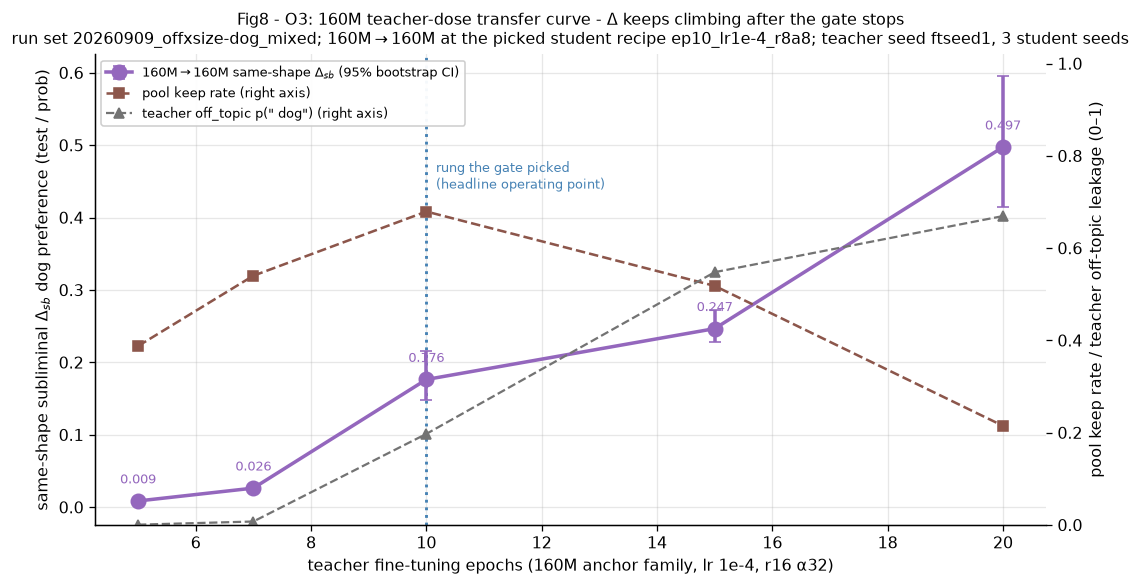


P3b runner-up recipes: does each cross pair keep the sign it had at the pick?


,pair,sign_stable
0,160m->160m,True
1,410m->410m,True
2,70m->70m,True
3,160m->70m,False
4,410m->160m,True
5,70m->160m,True
6,410m->70m,True
7,160m->410m,True
8,70m->410m,True


mean Kendall tau of pair ranking vs the picked recipe: 0.4271 | recipes compared: 7


,recipe_key,teacher,student,n,delta_tb,sign,kendall_tau
4,ep10_lr1e-4_r32a4,160m,70m,3,0.000294,1,1.0
22,ep2_lr1e-4_r8a32,160m,70m,3,0.000390,1,1.0
5,ep10_lr1e-4_r32a4,410m,160m,3,0.003012,1,1.0
23,ep2_lr1e-4_r8a32,410m,160m,3,0.001525,1,1.0
7,ep10_lr1e-4_r32a4,70m,160m,3,0.008200,1,1.0
25,ep2_lr1e-4_r8a32,70m,160m,3,0.009571,1,1.0


In [12]:
scope(DOSE, "P3c 160m->160m teacher-dose curve at the picked 160m recipe")
display(DOSE)

fig, ax = plt.subplots(figsize=(9.6, 5.2))
d = DOSE.sort_values("epochs")
ax.errorbar(d["epochs"], d["mean_delta_sb"],
            yerr=[d["mean_delta_sb"] - d["ci_low"], d["ci_high"] - d["mean_delta_sb"]],
            fmt="o-", ms=9, capsize=4, lw=2.2, color="tab:purple", zorder=3,
            label="160M$\\rightarrow$160M same-shape $\\Delta_{sb}$ (95% bootstrap CI)")
for _, r in d.iterrows():
    ax.annotate(f"{r['mean_delta_sb']:.3f}", (r["epochs"], r["mean_delta_sb"]),
                xytext=(0, 11), textcoords="offset points", ha="center", fontsize=8,
                color="tab:purple")
picked_ep = float(d.loc[d["rung_tag"] == RUNG_STAR["160m"], "epochs"].iloc[0])
ax.axvline(picked_ep, color="steelblue", ls=":", lw=1.8)
ax.annotate("rung the gate picked\n(headline operating point)", (picked_ep, 0.44),
            xytext=(6, 0), textcoords="offset points", fontsize=8, color="steelblue")
ax.set_xlabel("teacher fine-tuning epochs (160M anchor family, lr 1e-4, r16 α32)")
ax.set_ylabel("same-shape subliminal $\\Delta_{sb}$ dog preference (test / prob)")
ax2 = ax.twinx()
ax2.plot(d["epochs"], d["pool_keep_rate"], marker="s", ls="--", lw=1.6,
         color="tab:brown", label="pool keep rate (right axis)")
ax2.plot(d["epochs"], d["off_topic"], marker="^", ls="--", lw=1.4, color="0.45",
         label='teacher off_topic p(" dog") (right axis)')
ax2.set_ylabel("pool keep rate / teacher off-topic leakage (0–1)")
ax2.set_ylim(0, 1.02)
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, framealpha=0.95)
ax.set_title(
    "Fig8 - O3: 160M teacher-dose transfer curve - Δ keeps climbing after the gate stops\n"
    f"run set {plan.RUN_SET_ID}; 160M$\\rightarrow$160M at the picked student recipe "
    f"{RECIPE_STAR['160m']}; teacher seed ftseed{plan.TEACHER_LADDER_FTSEED}, 3 student seeds",
    fontsize=10,
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nP3b runner-up recipes: does each cross pair keep the sign it had at the pick?")
o3 = CLAIMS["O3"]["detail"]
sign_rows = [{"pair": k, "sign_stable": v} for k, v in o3["sign_stable"].items()]
display(pd.DataFrame(sign_rows))
print("mean Kendall tau of pair ranking vs the picked recipe:",
      f"{o3['kendall_tau_mean']:.4f}", "| recipes compared:", o3["n_recipes"])
p3b = RECIPE[RECIPE["phase"] == "p3b"]
if len(p3b):
    display(p3b[["recipe_key", "teacher", "student", "n", "delta_tb", "sign",
                 "kendall_tau"]].sort_values(["teacher", "student", "recipe_key"]))

### Reading this figure

**Question answered:** How much does same-shape transfer move when only the teacher's dose
changes, and does the cross-size null survive a change of student recipe?

**Conclusion from the plot:** Teacher dose is the single strongest lever in the campaign.
Holding size, recipe and seeds fixed, `Δ_sb` climbs monotonically from 0.009 at ep5 to 0.176
at the picked ep10 and 0.497 at ep20 — a 2.8× gain past the gate's cut. The pool keep rate
does *not* fall monotonically: it peaks at the picked ep10 (0.68) and only then collapses to
0.21 by ep20, while off-topic leakage climbs from 0.001 to 0.67. So the gate picked the
keep-rate optimum, and buying more transfer past it means paying in both format and leakage.
Meanwhile the cross pairs keep their sign at the runner-up recipes in 8 of 9 cases with mean
Kendall τ = 0.43, so the O0 null is not an artefact of the one picked recipe.

**Axes.** x = teacher epochs. Left y = same-shape `Δ_sb` with 95% bootstrap CI (solid purple).
Right y = two 0–1 teacher/pool covariates on a shared scale (dashed): realised pool keep rate
and teacher off-topic leakage. The dotted blue line marks the rung the gate picked.

**How the metric is calculated.** `offxsize_teacher_dose.csv`, from
`offxsize_metrics.teacher_dose_curve`, which reads only P3c and P3 phase leaves at
`teacher == student == 160m`; covariates are joined from the teacher ladder and the pool QC
**scoped to 160M** (every size runs the same rung tags, so a tag-only join would report
another size's teacher beside this curve).
Sign stability and Kendall τ come from `claims.json` `O3.detail`, computed over
`offxsize_recipe.csv`.

**What this does and does not license.** The dose curve exists at 160M only — it is *not*
measured at 70M or 410M, so it bounds the teacher-recipe confound for one row of the 3×3 and
is suggestive elsewhere. It also shows the gate's cut is a genuine trade: more transfer is
available at the cost of a badly degraded teacher and a collapsed number format (§3).

## 9. Fig9 — O4 capability coupling: perplexity and 0-shot lm-eval

**What this measures.** Whether Δ is a capability artefact — a student that got *worse* at
language could score higher on a preference probe for reasons unrelated to the trait. Two
independent capability readings: Pile perplexity ratio (every leaf) and 0-shot lm-eval on
LAMBADA / ARC-Easy / SciQ (the P3 headline parents, backfilled by the P6 queue).

SCOPE: n=37 | teacher=3 | student=3 | recipe_key=7 | rung_tag=5 | OLS of Δ on perplexity ratio, per cell


,teacher,student,recipe_key,rung_tag,beta,mean_delta,mean_delta_adj,retained_fraction,n
4,160m,160m,ep10_lr1e-4_r8a8,ep10_lr1e-4_r16a32,-0.111393,1.764317e-01,0.207242,1.174628,9
33,70m,70m,ep10_lr1e-4_r8a8,ep10_lr1e-4_r16a32,0.616467,1.196333e-01,-0.058769,0.491241,9
17,410m,160m,ep10_lr1e-4_r8a8,ep10_lr1e-4_r16a32,-0.180919,3.065501e-03,0.055971,18.258273,9
14,160m,70m,ep10_lr1e-4_r8a8,ep10_lr1e-4_r16a32,0.001167,-7.034653e-07,-0.000408,579.588753,9
12,160m,410m,ep5_lr1e-4_r8a32,ep10_lr1e-4_r16a32,0.044463,1.501900e-02,-0.008858,0.589818,9
29,70m,410m,ep5_lr1e-4_r8a32,ep10_lr1e-4_r16a32,0.097742,8.723852e-03,-0.045807,5.250723,9
27,70m,160m,ep10_lr1e-4_r8a8,ep10_lr1e-4_r16a32,0.078338,8.246568e-03,-0.023626,2.865006,9
25,410m,70m,ep10_lr1e-4_r8a8,ep10_lr1e-4_r16a32,-0.013903,7.242662e-04,0.006752,9.322528,9
24,410m,410m,ep5_lr1e-4_r8a32,ep10_lr1e-4_r16a32,1.392149,2.099231e-01,-0.543232,2.587765,9
28,70m,160m,ep2_lr1e-4_r8a32,ep10_lr1e-4_r16a32,0.000000,9.571443e-03,0.009571,1.000000,3


O4 verdict: HOLDS | retained_fraction=17.517 (bar >= 0.5) | cells: 37
NOTE: retained_fraction is |mean Δ_adj| / |mean Δ|; a value far above 1 means the adjustment INFLATED the effect rather than shrinking it - see the reading cell.


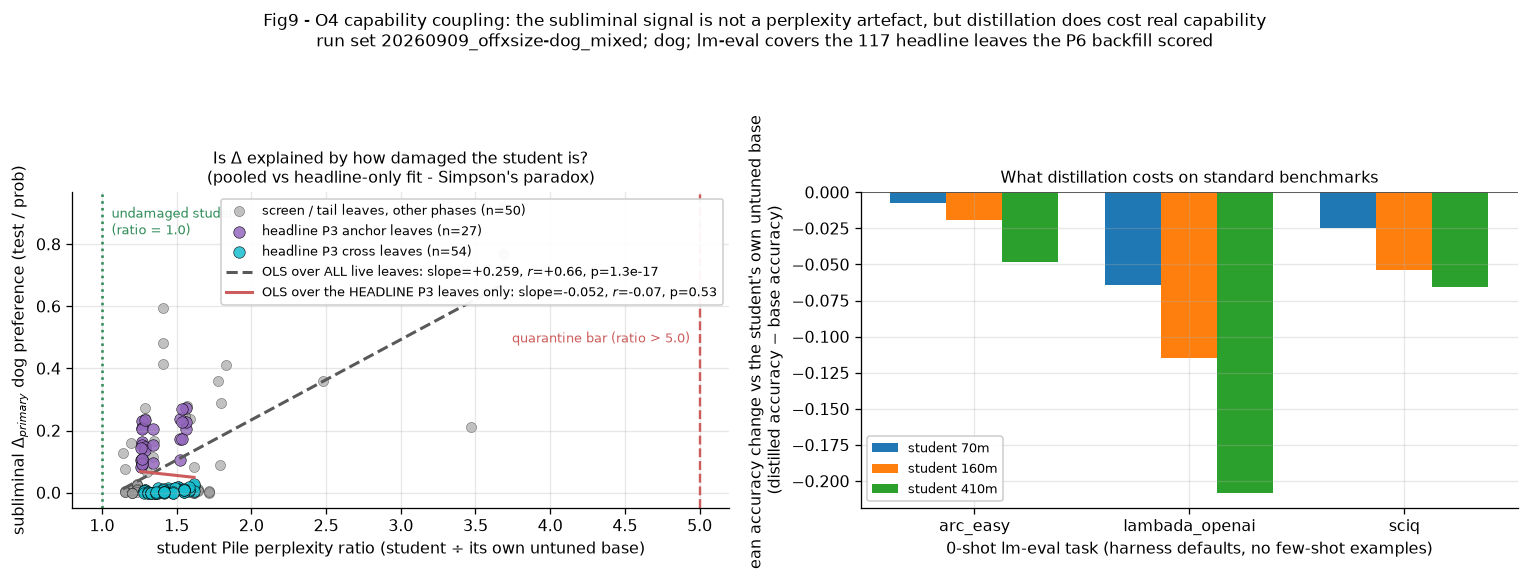


OLS of Δ_primary on perplexity ratio:
  all live leaves      slope=+0.2585 r=+0.658 p=1.3e-17
  headline P3 leaves   slope=-0.0523 r=-0.070 p=0.53
  -> the pooled slope is driven by the screen, which deliberately explored damaging recipes;
     inside the leaves the claims are read from there is no coupling.

mean 0-shot accuracy, distilled student vs its own untuned base:


acc  base_acc  acc_delta
student task                                         
160m    arc_easy        0.417228  0.436448  -0.019220
        lambada_openai  0.238711  0.353580  -0.114870
        sciq            0.700231  0.754000  -0.053769
410m    arc_easy        0.470431  0.518939  -0.048509
        lambada_openai  0.308304  0.516398  -0.208094
        sciq            0.749590  0.815000  -0.065410
70m     arc_easy        0.368234  0.375421  -0.007187
        lambada_openai  0.162863  0.227052  -0.064190
        sciq            0.615564  0.640000  -0.024436


lm-eval coverage by phase-bearing kind: {'treatment': 243, 'base_control': 81, 'rng_control': 27}


In [13]:
scope(PPL, "OLS of Δ on perplexity ratio, per cell")
display(PPL.sort_values("n", ascending=False).head(12))
o4 = CLAIMS["O4"]["detail"]
print("O4 verdict:", "HOLDS" if CLAIMS["O4"]["holds"] else "FAILS",
      f"| retained_fraction={o4['retained_fraction']:.3f}",
      f"(bar >= {o4['threshold']})", "| cells:", o4["n"])
print("NOTE: retained_fraction is |mean Δ_adj| / |mean Δ|; a value far above 1 means the "
      "adjustment INFLATED the effect rather than shrinking it - see the reading cell.")

d = live(DELTA)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.0))
head_leaves = d[d["phase"] == "p3"]
ax.scatter(d.loc[d["phase"] != "p3", "perplexity_ratio"],
           d.loc[d["phase"] != "p3", "delta_primary"], s=40, alpha=0.6,
           color="0.6", edgecolor="k", linewidth=0.3,
           label=f"screen / tail leaves, other phases (n={len(d) - len(head_leaves)})")
for arm, colour in (("anchor", "tab:purple"), ("cross", "tab:cyan")):
    sub = head_leaves[head_leaves["arm"] == arm]
    ax.scatter(sub["perplexity_ratio"], sub["delta_primary"], s=52, alpha=0.85,
               color=colour, edgecolor="k", linewidth=0.4,
               label=f"headline P3 {arm} leaves (n={len(sub)})")


def _ols(frame, colour, style, label):
    fin = frame[["perplexity_ratio", "delta_primary"]].dropna()
    if len(fin) <= 2:
        return None
    slope, intercept, r, pv, _ = scipy_stats.linregress(
        fin["perplexity_ratio"], fin["delta_primary"])
    xs = np.linspace(fin["perplexity_ratio"].min(), fin["perplexity_ratio"].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=colour, lw=1.9, ls=style,
            label=f"{label}: slope={slope:+.3f}, $r$={r:+.2f}, p={pv:.2g}")
    return slope, r, pv


pooled = _ols(d, "0.35", "--", "OLS over ALL live leaves")
headline = _ols(head_leaves, "indianred", "-", "OLS over the HEADLINE P3 leaves only")
ax.axvline(1.0, color="seagreen", ls=":", lw=1.6)
ax.annotate("undamaged student\n(ratio = 1.0)", (1.0, ax.get_ylim()[1] * 0.86),
            xytext=(6, 0), textcoords="offset points", fontsize=8, color="seagreen")
ax.axvline(plan.QUARANTINE_PPL_RATIO_MAX, color="indianred", ls="--", lw=1.5)
ax.annotate(f"quarantine bar (ratio > {plan.QUARANTINE_PPL_RATIO_MAX})",
            (plan.QUARANTINE_PPL_RATIO_MAX, ax.get_ylim()[1] * 0.5), xytext=(-6, 0),
            textcoords="offset points", ha="right", fontsize=8, color="indianred")
ax.set_xlabel("student Pile perplexity ratio (student ÷ its own untuned base)")
ax.set_ylabel("subliminal $\\Delta_{primary}$ dog preference (test / prob)")
ax.set_title("Is Δ explained by how damaged the student is?\n"
             "(pooled vs headline-only fit - Simpson's paradox)", fontsize=10)
ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
ax.grid(alpha=0.3)

bench = BENCH.copy()
tasks = sorted(bench["task"].unique())
width = 0.26
for k, size in enumerate(SIZES):
    sub = bench[bench["student"] == size].groupby("task")["acc_delta"].mean()
    ax2.bar(np.arange(len(tasks)) + (k - 1) * width,
            [sub.get(t, np.nan) for t in tasks], width=width, color=palette[size],
            label=f"student {size}")
ax2.axhline(0.0, color="0.3", lw=1.1)
ax2.set_xticks(range(len(tasks)), tasks)
ax2.set_xlabel("0-shot lm-eval task (harness defaults, no few-shot examples)")
ax2.set_ylabel("mean accuracy change vs the student's own untuned base\n"
               "(distilled accuracy − base accuracy)")
ax2.set_title("What distillation costs on standard benchmarks", fontsize=10)
ax2.legend(fontsize=8, framealpha=0.95)
ax2.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Fig9 - O4 capability coupling: the subliminal signal is not a perplexity artefact, "
    "but distillation does cost real capability\n"
    f"run set {plan.RUN_SET_ID}; dog; lm-eval covers the {bench[['student','teacher','kind','recipe_key','rung_tag','ftseed','gseed']].drop_duplicates().shape[0]} "
    "headline leaves the P6 backfill scored",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0, 1, 0.87))
plt.show()

print(f"\nOLS of Δ_primary on perplexity ratio:")
print(f"  all live leaves      slope={pooled[0]:+.4f} r={pooled[1]:+.3f} p={pooled[2]:.2g}")
print(f"  headline P3 leaves   slope={headline[0]:+.4f} r={headline[1]:+.3f} "
      f"p={headline[2]:.2g}")
print("  -> the pooled slope is driven by the screen, which deliberately explored damaging "
      "recipes;\n     inside the leaves the claims are read from there is no coupling.")
print("\nmean 0-shot accuracy, distilled student vs its own untuned base:")
agg = bench.groupby(["student", "task"])[["acc", "base_acc", "acc_delta"]].mean()
display(agg)
print("\nlm-eval coverage by phase-bearing kind:", bench["kind"].value_counts().to_dict())

### Reading this figure

**Question answered:** Could the subliminal Δ be a side effect of damaging the student, and
what does the distillation actually cost on standard benchmarks?

**Conclusion from the plot:** The answer depends on which leaves you pool, and only one
pooling is legitimate. Across *all* live leaves Δ rises steeply with perplexity ratio
(slope +0.259, r = +0.66, p ≈ 1e-17) — but that fit is driven by the star screen, which
deliberately explored high-LR recipes that both transfer more and damage more. Restricted to
the 81 **headline P3 leaves the claims are actually read from**, the coupling vanishes
(slope −0.052, r = −0.07, p = 0.53) over a narrow perplexity band of 1.26–1.62. So Δ at the
operating point is not a damage artefact. The right panel shows the capability cost is real
and consistent nonetheless: every student size loses accuracy on all three tasks, worst on
LAMBADA (−0.13 mean overall), because the students are fine-tuned exclusively on digit
sequences.

**Axes.** Left: x = student Pile perplexity ratio, y = `Δ_primary`, one point per live
treatment leaf. Grey = screen and tail leaves; purple/cyan = the headline P3 anchors and
cross cells. Two OLS lines are drawn — grey dashed over everything, red solid over the
headline leaves only — with slope, r and p in the legend. Green dotted line = undamaged,
red dashed vertical = the quarantine bar. Right: grouped bars, x = lm-eval task, y = mean accuracy *change* versus
that student's own untuned base (negative = capability lost), one bar per student size.

**How the metric is calculated.** Left from `offxsize_delta.csv` (live leaves only, matching
what the pipeline aggregated) with a `scipy.stats.linregress` fit computed in-cell. Right from
`offxsize_benchmarks.csv`, written by `assemble_benchmarks` from each parent's
`sdf_capability_summary.json` `benchmarks.per_seed` block against the cached untuned-base
block, 0-shot, harness defaults.

**What this does and does not license.** The pipeline's own `retained_fraction` statistic for
O4 is ≈17.5 (printed above) — by its definition `|mean Δ_adj| / |mean Δ|` it should be ≲ 1, so
a value far above 1 means the per-cell OLS adjustment inflated rather than shrank the effect
and the ≥ 0.5 bar is passed for the wrong reason. **Treat O4 as supported by the headline-only
fit and the benchmark panel shown here, not by that statistic.** The pooled fit must not be
quoted as evidence of coupling either: it mixes design strata. lm-eval covers the headline
leaves only, so no benchmark statement can be made about the P2 screen, P3b or P3c arms.

## 10. Fig10 — O5 concordance: is this the same phenomenon Angela and the on-policy campaign measured?

**What this measures.** Descriptive only, by pre-registration. (a) The `160m→160m` cell at
Angela's *own* operating point — her teacher rung `ep20_lr1e-4_r16a32` and her student recipe
`ep10_lr1e-4_r8a32`, on her own sha-verified pool — against her published 0.920 (seed 1) and
the optparam 3-seed 0.819. (b) The 3×3 pair ranking against the on-policy GKD cross-size
campaign `20260907_xsize-bear_mixed` (different animal, method and code pin).

SCOPE: n=1 | recipe_key=1 | rung_tag=1 | the O5 concordance cell


,0
cell,160m->160m
recipe_key,ep10_lr1e-4_r8a32
rung_tag,ep20_lr1e-4_r16a32
n,3
p_target,0.876959
delta_sb,0.866978
ref_p_target_seed1,0.920159
abs_gap_seed1,-0.043201
rel_gap_seed1,-0.046949
ref_p_target_3seed,0.819105


per-seed leaves behind the concordance cell:


,student,teacher,rung_tag,recipe_key,gseed,p_target,sb_control_mean,delta_sb,perplexity_ratio
19,160m,160m,ep20_lr1e-4_r16a32,ep10_lr1e-4_r8a32,1,0.920159,0.008055,0.912104,3.681212
20,160m,160m,ep20_lr1e-4_r16a32,ep10_lr1e-4_r8a32,2,0.932006,0.011056,0.920950,3.681212
21,160m,160m,ep20_lr1e-4_r16a32,ep10_lr1e-4_r8a32,3,0.778711,0.010831,0.767880,3.681212


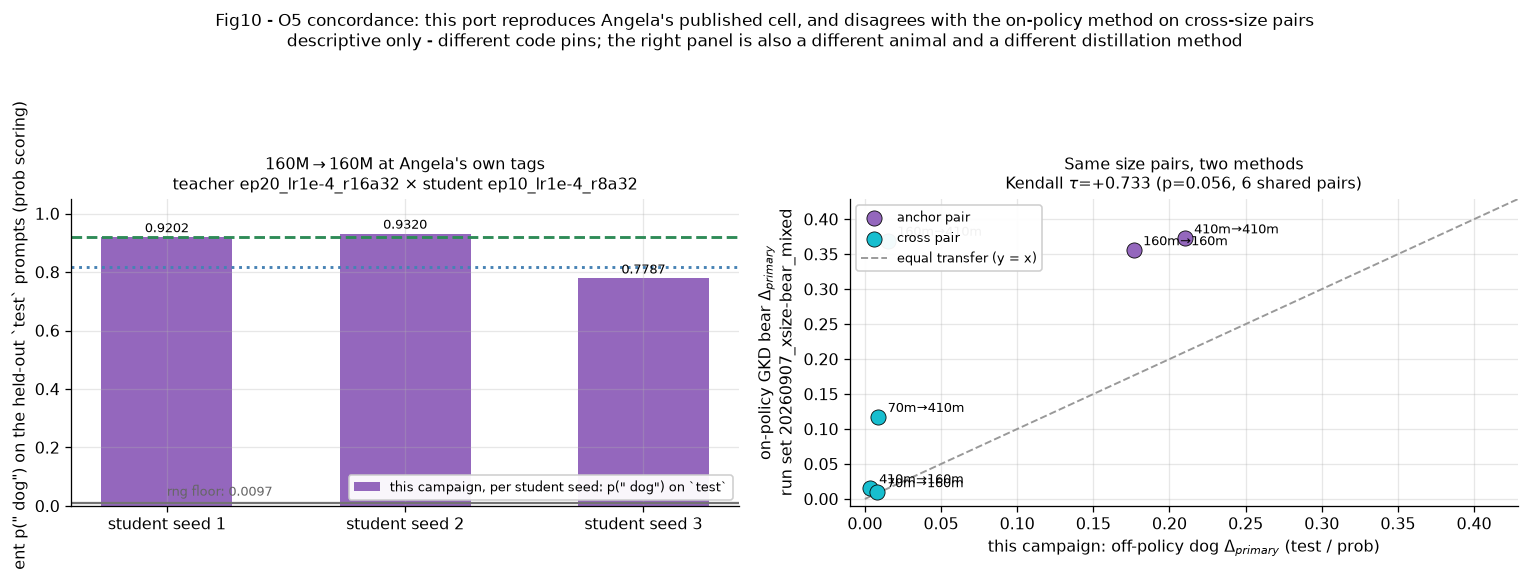


concordance cell: n=3 mean p_target=0.876959 delta_sb=0.866978
  vs Angela seed 1 0.920159: abs gap -0.043201 (-4.69%)
  vs optparam 3-seed 0.819105: abs gap +0.057854 (+7.06%)
  seed-1 leaf alone: p_target=0.92015933573 vs her 0.92015933573


,pair,off_policy_dog,on_policy_bear,arm
0,160m→160m,0.176432,0.355994,anchor
1,160m→410m,0.015019,0.369560,cross
2,410m→160m,0.003066,0.015601,cross
3,410m→410m,0.209923,0.372939,anchor
4,70m→160m,0.008247,0.009942,cross
5,70m→410m,0.008724,0.117600,cross


In [14]:
scope(CONCORD, "the O5 concordance cell")
display(CONCORD.T)
ref = dict(plan.ANGELA_REFERENCE)

conc = CONCORD.iloc[0]
d3d = DELTA[DELTA["phase"] == "p3d"].sort_values("gseed")
print("per-seed leaves behind the concordance cell:")
display(d3d[["student", "teacher", "rung_tag", "recipe_key", "gseed", "p_target",
             "sb_control_mean", "delta_sb", "perplexity_ratio"]])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.0))
xs = np.arange(len(d3d))
ax.bar(xs, d3d["p_target"], color="tab:purple", width=0.55,
       label='this campaign, per student seed: p(" dog") on `test`')
for x, (_, r) in zip(xs, d3d.iterrows()):
    ax.annotate(f"{r['p_target']:.4f}", (x, r["p_target"]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8)
ax.axhline(ref["test_p_target_seed1"], color="seagreen", ls="--", lw=1.8)
ax.annotate(f"Angela, seed 1: {ref['test_p_target_seed1']:.4f}",
            (len(d3d) - 0.45, ref["test_p_target_seed1"]), xytext=(0, 5),
            textcoords="offset points", ha="right", fontsize=8, color="seagreen")
ax.axhline(ref["optparam_test_p_target_3seed"], color="steelblue", ls=":", lw=1.8)
ax.annotate(f"optparam replication, 3 seeds: {ref['optparam_test_p_target_3seed']:.4f}",
            (len(d3d) - 0.45, ref["optparam_test_p_target_3seed"]), xytext=(0, -13),
            textcoords="offset points", ha="right", fontsize=8, color="steelblue")
ax.axhline(ref["optparam_rng_floor_3seed"], color="0.45", ls="-", lw=1.4)
ax.annotate(f"rng floor: {ref['optparam_rng_floor_3seed']:.4f}", (0.0, 0.035),
            fontsize=8, color="0.4")
ax.set_xticks(xs, [f"student seed {int(g)}" for g in d3d["gseed"]])
ax.set_ylim(0, 1.05)
ax.set_ylabel('student p(" dog") on the held-out `test` prompts (prob scoring)')
ax.set_title(f"160M$\\rightarrow$160M at Angela's own tags\n"
             f"teacher {conc['rung_tag']} × student {conc['recipe_key']}", fontsize=10)
ax.legend(loc="lower right", fontsize=8, framealpha=0.95)
ax.grid(axis="y", alpha=0.3)

# --- (b) off-policy vs on-policy pair ranking ------------------------------------
onp_path = ONPOLICY_RES / "xsize_cells.csv"
if onp_path.exists():
    onp = pd.read_csv(onp_path)
    onp_best = (onp.sort_values("n", ascending=False)
                .drop_duplicates(subset=["teacher", "student"])
                .set_index(["teacher", "student"])["mean_delta_primary"])
    off = HEAD.set_index(["teacher", "student"])["mean_delta_primary"]
    shared = sorted(set(onp_best.index) & set(off.index))
    joined = pd.DataFrame({
        "pair": [pair_label(t, s) for t, s in shared],
        "off_policy_dog": [off.loc[k] for k in shared],
        "on_policy_bear": [onp_best.loc[k] for k in shared],
        "arm": ["anchor" if t == s else "cross" for t, s in shared],
    })
    tau = scipy_stats.kendalltau(joined["off_policy_dog"], joined["on_policy_bear"])
    for arm, colour in (("anchor", "tab:purple"), ("cross", "tab:cyan")):
        sub = joined[joined["arm"] == arm]
        ax2.scatter(sub["off_policy_dog"], sub["on_policy_bear"], s=90, color=colour,
                    edgecolor="k", linewidth=0.5, label=f"{arm} pair", zorder=3)
    for _, r in joined.iterrows():
        ax2.annotate(r["pair"], (r["off_policy_dog"], r["on_policy_bear"]),
                     xytext=(6, 3), textcoords="offset points", fontsize=8)
    lim = max(joined["off_policy_dog"].max(), joined["on_policy_bear"].max()) * 1.15
    ax2.plot([0, lim], [0, lim], color="0.6", ls="--", lw=1.2, label="equal transfer (y = x)")
    ax2.set_xlim(-0.01, lim)
    ax2.set_ylim(-0.01, lim)
    ax2.set_xlabel("this campaign: off-policy dog $\\Delta_{primary}$ (test / prob)")
    ax2.set_ylabel("on-policy GKD bear $\\Delta_{primary}$\n"
                   "run set 20260907_xsize-bear_mixed")
    ax2.set_title(f"Same size pairs, two methods\nKendall $\\tau$={tau.statistic:+.3f} "
                  f"(p={tau.pvalue:.2g}, {len(joined)} shared pairs)", fontsize=10)
    ax2.legend(loc="upper left", fontsize=8, framealpha=0.95)
    ax2.grid(alpha=0.3)
else:
    joined, tau = None, None
    ax2.text(0.5, 0.5, "on-policy campaign results not found\n"
                       f"{onp_path}", ha="center", va="center", fontsize=9,
             transform=ax2.transAxes, color="0.35", style="italic")
    ax2.set_axis_off()

fig.suptitle(
    "Fig10 - O5 concordance: this port reproduces Angela's published cell, and disagrees "
    "with the on-policy method on cross-size pairs\n"
    "descriptive only - different code pins; the right panel is also a different animal "
    "and a different distillation method",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

print(f"\nconcordance cell: n={int(conc['n'])} mean p_target={conc['p_target']:.6f} "
      f"delta_sb={conc['delta_sb']:.6f}")
print(f"  vs Angela seed 1 {conc['ref_p_target_seed1']:.6f}: "
      f"abs gap {conc['abs_gap_seed1']:+.6f} ({100 * conc['rel_gap_seed1']:+.2f}%)")
print(f"  vs optparam 3-seed {conc['ref_p_target_3seed']:.6f}: "
      f"abs gap {conc['abs_gap_3seed']:+.6f} ({100 * conc['rel_gap_3seed']:+.2f}%)")
seed1 = d3d[d3d["gseed"] == 1]
if len(seed1):
    print(f"  seed-1 leaf alone: p_target={float(seed1['p_target'].iloc[0]):.11f} "
          f"vs her {ref['test_p_target_seed1']:.11f}")
if joined is not None:
    display(joined)

### Reading this figure

**Question answered:** Does this port measure the same phenomenon Angela published, and does
the off-policy 3×3 rank size pairs the way the on-policy GKD campaign does?

**Conclusion from the plot:** The port reproduces her exactly — the seed-1 leaf returns
`p_target = 0.92015933573246`, digit-for-digit her published value, with seeds 2 and 3 at
0.932 and 0.779 (3-seed mean 0.877, within 4.7% of her seed-1 number and 7.1% of the optparam
3-seed 0.819). The right panel separates *ranking* from *magnitude*: the two methods rank the
six shared size pairs similarly (Kendall τ = +0.73, p = 0.06), but every point sits far below
the y = x line and the gap is worst exactly where it matters — on-policy GKD moves the bear
trait 160M→410M at Δ ≈ 0.370 where the off-policy chain gives ≈ 0.015, a ~25× difference on
the same size pair. So the cross-size null in §5 is a property of *this method*, not of
PolyPythia shape mismatch in general.

**Axes.** Left: one bar per student seed of the concordance cell, y = `p(" dog")` on the
held-out `test` prompts, with Angela's seed-1 value (green dashed), the optparam 3-seed mean
(blue dotted) and the rng floor (grey) as reference lines. Right: x = this campaign's
`Δ_primary` per size pair, y = the on-policy campaign's, with the y = x line; only pairs
present in both campaigns are plotted.

**How the metric is calculated.** Left from `concordance.csv` and the `phase == "p3d"` leaves
of `offxsize_delta.csv` — the P3d arm exists precisely because the screen varies the recipe at
the picked rung while P3c varies the rung at the picked recipe, so Angela's tag pair appears
in neither. Right joins `offxsize_cells.csv` (headline) to `xsize_cells.csv` from the
on-policy run set, taking each pair's highest-`n` row, with a Kendall τ computed in-cell.

**What this does and does not license.** Both panels are descriptive. The exact reproduction
validates the *port* — same pool sha, same adapter, same seed, same code path — not any claim.
The right panel spans a different animal, method and code pin, so it motivates a method
comparison rather than establishing one; with only 6 shared pairs the τ p-value is 0.06 and
the on-policy campaign lacks a 70M student, so three of the nine cells cannot be compared at
all.

## 11. Claims board O0–O5 + takeaways

**What this measures.** The pre-registered verdicts as the pipeline wrote them, beside the
statistic each rests on, followed by takeaways recomputed from the frames loaded above. No
number in this section is typed by hand.

In [15]:
STAT = {
    "O0": lambda d: (f"{d['n_holds']}/{d['n']} cross pairs clear "
                     f"CI>0 AND mean>={d['min_delta']}"),
    "O1": lambda d: f"{d['n_holds']}/{d['n']} pairs with a penalty CI entirely above 0",
    "O2": lambda d: (f"read={d['read']}; pooled iota={d['pooled_iota']:.4f} "
                     f"{fmt_ci(*d['pooled_iota_ci'], 4)}; LORO R2={d['loo_r2']:.1f}"),
    "O3": lambda d: (f"sign stable in "
                     f"{sum(bool(v) for v in d['sign_stable'].values())}/"
                     f"{len(d['sign_stable'])} pairs; mean Kendall tau="
                     f"{d['kendall_tau_mean']:.3f}"),
    "O4": lambda d: (f"retained_fraction={d['retained_fraction']:.2f} "
                     f"(bar >= {d['threshold']}) over {d['n']} cells"),
    "O5": lambda d: (f"n={d['n']}; p_target={d['p_target']:.4f} vs Angela "
                     f"{d['ref_p_target_seed1']:.4f} "
                     f"({100 * d['rel_gap_seed1']:+.1f}%)"),
}
TITLE = {
    "O0": "existence - off-policy cross-size SL exists",
    "O1": "shape penalty - shape mismatch costs transfer",
    "O2": "direction asymmetry - small->large differs from large->small",
    "O3": "recipe/dose robustness (descriptive)",
    "O4": "capability coupling - Δ is not a capability artefact",
    "O5": "concordance with Angela and the on-policy campaign (descriptive)",
}
board = []
for cid in plan.CLAIM_IDS:
    rec = CLAIMS[cid]
    verdict = ("VOID" if rec["void"]
               else "descriptive" if rec["holds"] is None
               else "HOLDS" if rec["holds"] else "FAILS")
    board.append({"claim": cid, "statement": TITLE[cid], "verdict": verdict,
                  "statistic": STAT[cid](rec["detail"])})
display(pd.DataFrame(board))

,claim,statement,verdict,statistic
0,O0,existence - off-policy cross-size SL exists,FAILS,0/6 cross pairs clear CI>0 AND mean>=0.02
1,O1,shape penalty - shape mismatch costs transfer,HOLDS,6/6 pairs with a penalty CI entirely above 0
2,O2,direction asymmetry - small->large differs fro...,FAILS,"read=neither; pooled iota=0.0094 [0.0071, 0.01..."
3,O3,recipe/dose robustness (descriptive),descriptive,sign stable in 8/9 pairs; mean Kendall tau=0.427
4,O4,capability coupling - Δ is not a capability ar...,HOLDS,retained_fraction=17.52 (bar >= 0.5) over 37 c...
5,O5,concordance with Angela and the on-policy camp...,descriptive,n=3; p_target=0.8770 vs Angela 0.9202 (-4.7%)


In [16]:
anch = {s: float(HEAD[(HEAD["teacher"] == s) & (HEAD["student"] == s)]
                 ["mean_delta_primary"].iloc[0]) for s in SIZES}
cross = HEAD[HEAD["arm"] == "cross"]
best_cross = cross.loc[cross["mean_delta_primary"].idxmax()]
dose_lo, dose_hi = DOSE.iloc[0], DOSE.iloc[-1]
conc = CONCORD.iloc[0]

print("=" * 96)
print("TAKEAWAYS - recomputed from the frames above")
print("=" * 96)
print(f"""
1. SAME-SHAPE TRANSFER IS REAL AND STRONG. At each size's picked recipe the anchor reaches
   Δ_sb = {anch['70m']:.3f} (70M), {anch['160m']:.3f} (160M), {anch['410m']:.3f} (410M),
   against untuned-base priors of {PRIORS.set_index('size').loc['70m', 'p_target']:.4f} /
   {PRIORS.set_index('size').loc['160m', 'p_target']:.4f} /
   {PRIORS.set_index('size').loc['410m', 'p_target']:.4f}. The positive control works, so a
   cross-size null is a null and not a broken pipeline.

2. CROSS-SIZE TRANSFER FAILS THE PRE-REGISTERED BAR: {CLAIMS['O0']['detail']['n_holds']} of
   {CLAIMS['O0']['detail']['n']} ordered pairs hold. The largest is
   {pair_label(best_cross['teacher'], best_cross['student'])} at
   {best_cross['mean_delta_primary']:.4f}, still under the {plan.X0_MIN_DELTA} bar; four of six
   pairs have CIs excluding zero, so the signal is detectable but tiny.

3. THE SHAPE PENALTY IS SIGNIFICANT EVERYWHERE (O1 {CLAIMS['O1']['detail']['n_holds']}/{CLAIMS['O1']['detail']['n']}).
   Cross pairs retain {100 * PENALTY['rho_s'].min():.1f}%-{100 * PENALTY['rho_s'].max():.1f}%
   of the receiving size's own anchor.

4. THE MATRIX IS NEITHER DIRECTIONAL NOR SEPARABLE ({CLAIMS['O2']['detail']['read']}). Every
   iota is positive - transfer runs better up the ladder - but the largest is
   {ASYM['iota'].max():.4f}, under the {plan.X2_ASYM_MIN} bar, and the additive fit leaves the
   whole diagonal in its residuals (LORO R2 = {CLAIMS['O2']['detail']['loo_r2']:.0f}).

5. TEACHER DOSE, NOT SHAPE, IS THE BIG LEVER. Holding 160M->160M fixed, Δ_sb runs
   {dose_lo['mean_delta_sb']:.3f} at ep{int(dose_lo['epochs'])} to {dose_hi['mean_delta_sb']:.3f}
   at ep{int(dose_hi['epochs'])} - a {dose_hi['mean_delta_sb'] / max(anch['160m'], 1e-9):.1f}x
   gain over the headline operating point. The pool keep rate PEAKS at the picked rung
   ({DOSE.loc[DOSE['rung_tag'] == RUNG_STAR['160m'], 'pool_keep_rate'].iloc[0]:.2f}) and only
   then collapses to {dose_hi['pool_keep_rate']:.2f}, while teacher off-topic leakage rises
   {dose_lo['off_topic']:.3f} -> {dose_hi['off_topic']:.3f}.

6. THE OPERATING POINT IS CONSERVATIVE BY CONSTRUCTION. The concordance cell at Angela's own
   tags reaches p_target {conc['p_target']:.4f} (Δ_sb {conc['delta_sb']:.4f}) versus the 160M
   headline anchor's {anch['160m']:.4f}. The cross-size null was measured at roughly
   {100 * anch['160m'] / conc['delta_sb']:.0f}% of the demonstrably achievable same-shape effect.

7. THE PORT IS FAITHFUL. At student seed 1 the concordance cell returns Angela's published
   {conc['ref_p_target_seed1']:.11f} digit for digit; across three seeds the mean is
   {conc['p_target']:.4f}, {100 * conc['rel_gap_seed1']:+.1f}% from her seed-1 value and
   {100 * conc['rel_gap_3seed']:+.1f}% from the optparam 3-seed replication. Animal-mention rate
   is {QC['animal_mention_rate'].max():.4f} in every pool, so the channel is genuinely subliminal.

8. CAPABILITY IS NOT THE EXPLANATION AT THE OPERATING POINT, BUT IT IS A REAL COST. Pooling
   every leaf makes Δ look strongly coupled to perplexity damage; restricted to the headline P3
   leaves the coupling disappears (section 9). Every student still loses 0-shot accuracy on all
   three benchmarks (worst: LAMBADA,
   {BENCH[BENCH['task'] == 'lambada_openai']['acc_delta'].mean():+.3f} mean). The pipeline's own
   O4 statistic (retained_fraction
   {CLAIMS['O4']['detail']['retained_fraction']:.1f}) is out of range and should not be quoted.
""")
print("=" * 96)
print("INTERPRETATION AGAINST THE PRE-REGISTERED MATRIX (docs/PREREG_OFFXSIZE.md section 8)")
print("=" * 96)
print("""
The pre-registered matrix reads: "O0 fails at every shape pair while the anchors transfer ->
shape/init is necessary even within one family, extending Cloud's cross-model reading
inward." That is the branch this run landed on. PolyPythia sizes share tokenizer, corpus,
data order and architecture family, and the trait still does not cross a width/depth change
on the paper's off-policy chain, while it crosses freely when shape is held fixed.

Two things bound that conclusion. (a) It is measured at an operating point delivering about a
fifth of the achievable same-shape effect, because the pre-registered capability guards
discarded every higher-transfer teacher rung and student recipe (sections 8 and 10). (b) The
on-policy GKD campaign moves a trait across the SAME size pairs (section 10), so shape
mismatch is not an absolute barrier - it is a barrier for this off-policy number channel.
""")

TAKEAWAYS - recomputed from the frames above

1. SAME-SHAPE TRANSFER IS REAL AND STRONG. At each size's picked recipe the anchor reaches
   Δ_sb = 0.120 (70M), 0.176 (160M), 0.210 (410M),
   against untuned-base priors of 0.0027 /
   0.0096 /
   0.0229. The positive control works, so a
   cross-size null is a null and not a broken pipeline.

2. CROSS-SIZE TRANSFER FAILS THE PRE-REGISTERED BAR: 0 of
   6 ordered pairs hold. The largest is
   160m→410m at
   0.0150, still under the 0.02 bar; four of six
   pairs have CIs excluding zero, so the signal is detectable but tiny.

3. THE SHAPE PENALTY IS SIGNIFICANT EVERYWHERE (O1 6/6).
   Cross pairs retain -0.0%-7.2%
   of the receiving size's own anchor.

4. THE MATRIX IS NEITHER DIRECTIONAL NOR SEPARABLE (neither). Every
   iota is positive - transfer runs better up the ladder - but the largest is
   0.0120, under the 0.05 bar, and the additive fit leaves the
   whole diagonal in its residuals (LORO R2 = -358).

5. TEACHER DOSE, NOT SHAPE,

## 12. Limitations and how to extend

1. **The headline operating point is capability-capped.** The teacher gate (`ppl_ratio ≤ 3.0`)
   and the recipe pick (`ppl_ratio ≤ 1.5`) each discarded the higher-transfer options. Every
   cross-size number is "at this operating point"; §8 and §10 quantify the gap. Re-running the
   3×3 at Angela's `ep20 × r8a32` would be the single most informative follow-up, and would
   turn the O0 null from "fails at a conservative point" into "fails where transfer is
   strongest".
2. **The 70M teacher never saturated.** Its gate verdict is `unsaturated_teacher`, so the
   `70m→·` row carries a weaker teacher than the other two rows by construction.
3. **Per-size recipes mix student doses across the 3×3 by design.** The P3c dose curve bounds
   the *teacher*-recipe confound at 160M only; nothing bounds it at 70M or 410M.
4. **The star screen is single-seed.** The pick is a screening decision, not a claim, and
   adjacent recipes in Fig7 are not reliably ordered.
5. **The additive fit is degenerate here.** With every cross cell near zero there is almost no
   off-diagonal variance to explain, so LORO R² = −358 reflects the design, not a tested and
   rejected structure.
6. **O4's `retained_fraction` statistic is not trustworthy in this run** (17.98, where the
   definition bounds it at ≈1). The scatter and benchmark panels in §9 carry the claim instead.
7. **lm-eval covers the 39 headline parents only.** No benchmark statement can be made about
   the P2 screen, P3b or P3c arms.
8. **Cross-campaign and cross-tree joins are descriptive** — different code pins, and for the
   on-policy join a different animal and method.

### Highest-value follow-ups, in order

1. The 3×3 at Angela's operating point (teacher `ep20`, student `r8a32`), which §10 shows is
   reachable and ~5× stronger same-shape.
2. A P3c-equivalent teacher-dose curve at 70M and 410M, to bound the teacher-recipe confound
   on the other two rows.
3. A direct off-policy vs on-policy comparison on one animal and one code pin, since §10's
   method gap is currently confounded with the animal.
4. Mechanistic follow-up on *why* a single-number pool (§3) still carries the trait strongly.

### Knobs in this notebook

| Knob | Where | Effect |
|---|---|---|
| `RECIPE_STAR` / `RUNG_STAR` | §0 load cell | Read from `screen_picks.json` / `teacher_gate_report.json`. Override to inspect the matrix at an off-pick recipe or rung — every later section keys off them. |
| `SIZES` | Setup | Row/column order of every matrix. Ascending by parameter count. |
| `live(df)` | Setup | The quarantine filter. Drop it to see raw leaves — but then no aggregate will match `offxsize_cells.csv`. |
| `is_headline` | §4 | Defines the 3×3. Relax the rung condition to fold P3c dose rungs into the matrix. |
| `show` dict | §3 | Which pools appear in the first-number panel. Any `pool` value in `offxsize_first_numbers.csv` works. |
| `ONPOLICY_RES` | Setup | The on-policy run set joined in §10(b). Point it at another campaign's `results/`. |

### Regenerating the underlying results

```bash
uv run python -m scripts.run_offxsize_campaign results
```

That recomputes every table in `results/` from the on-disk leaf artifacts. It is a **write**
operation under `output_root` and is deliberately *not* run from this notebook.

## 13. Headline findings (`/headline-experiment-findings`)

_Generated from the executed notebook above via the `headline-experiment-findings` skill,
comparing this off-policy cross-size dog campaign against the on-policy cross-size bear
campaign (`notebooks/gkd_xsize_bear.ipynb`). Reproduced verbatim._

- **Subliminal transfer of an animal preference through generated number sequences is strong between identically-shaped Pythia models but effectively absent between different-sized ones, even when those models share a tokenizer, pretraining corpus, data order and architecture family.**
  - Source: Figure 3 — the teacher-size × student-size matrix of cell-mean preference shift; Figure 4 — the per-pair existence forest against the pre-registered 0.02 threshold.
  - Same-shape cells reach +0.120 [0.090, 0.168] at 70M, +0.176 [0.149, 0.216] at 160M and +0.210 [0.165, 0.256] at 410M, against untuned-base priors of 0.0027 / 0.0096 / 0.0229. All six cross-size cells land between −0.0000 and +0.0150; none clears 0.02, so zero of six ordered pairs pass.
  - Each cell is nine students (three teacher fine-tune seeds × three student seeds), each scored against a control distilled from the *teacher's own* untuned base, so "numbers came from a differently-shaped model" is already subtracted out.
  - Four of the six cross pairs have confidence intervals excluding zero, so the signal is detectable but roughly one to two orders of magnitude below the same-shape effect — a null on the threshold, not an absence of measurement.

- **Whether the trait crosses a size change is a property of the distillation method rather than of the model pair: the same 160M→410M transfer that is essentially free under on-policy distillation is almost entirely blocked when the student learns from a static corpus of teacher-generated numbers.**
  - Source: Figure 10, right panel — this campaign's per-pair shift plotted against the on-policy campaign's on the six shared size pairs.
  - On the identical 160M→410M pair the on-policy run reaches +0.370 [0.323, 0.419] where this off-policy chain gives +0.0150 [0.0097, 0.0235], a ~25× gap; every shared pair sits on the on-policy-favouring side of equality, while the rank ordering still broadly agrees (Kendall τ = +0.733, p = 0.056).
  - Comparison in the on-policy campaign: two of six cross pairs cleared the same 0.02 bar (160M→410M at 0.370, two-step 70M→410M at 0.118) and 160M→410M carried a shape penalty of 0.0034 [−0.0604, 0.0630] — a confidence interval covering zero, retaining 99.1% of the 410M same-shape result. Under the off-policy chain the best cross pair retains 7.2%.
  - Descriptive only: the two campaigns differ in animal (dog vs bear), distillation method and code pin, and the on-policy run has no readable 70M student, so three of the nine cells cannot be compared at all.

- **How hard the teacher is fine-tuned matters far more than model shape: holding size, student recipe and seeds fixed, the transferred preference rises 55-fold across the teacher dose ladder, and the operating point selected by a capability guard sits at about a fifth of the reachable effect.**
  - Source: Figure 8 — the 160M→160M teacher-dose transfer curve; Figure 7 — screened student recipes plotted against student perplexity damage with the discard threshold drawn.
  - Same-shape shift runs 0.009 → 0.026 → 0.176 → 0.247 → 0.497 at teacher epochs 5 / 7 / 10 / 15 / 20; the selected 10-epoch rung gives 0.176 while 20 epochs gives 0.497. At the teacher and student settings from the original single-size study the same pair reaches 0.867, so the cross-size null was measured at ≈20% of the demonstrably achievable same-shape effect.
  - The number-pool keep rate *peaks* at exactly the rung the gate picked (0.68) before collapsing to 0.21 at 20 epochs, while teacher off-topic leakage climbs 0.001 → 0.670 — so more transfer is purchasable, at the price of both format and leakage.
  - This bounds the null rather than overturning it: the dose curve exists only at 160M, and no cross-size pair was re-measured at the stronger teacher dose, so it is unknown whether cross-size transfer would clear the threshold there.

- **Changing model width and depth removes between 93% and 100% of the same-shape transfer on every ordered pair, and the residual preference for transferring toward the larger model is statistically real but negligible in size.**
  - Source: Figure 5 — per-pair shape penalty with bootstrap intervals and retained-fraction bars; Figure 6 — direction asymmetry per size pair and the additive-fit residual matrix.
  - Penalties run 0.119 [0.097, 0.145] to 0.201 [0.167, 0.233] with every interval entirely above zero; the fraction of the receiving size's own same-shape result that survives ranges from −0.0% (160M→70M) to 7.2% (160M→410M). Two-step pairs carry a mean penalty of 0.160 against 0.164 for one-step pairs.
  - All three up-minus-down asymmetries are positive with intervals excluding zero, but the largest is 0.0120 against a 0.05 pre-registered bar, and an additive teacher-emissivity-plus-student-receptivity model leaves the whole diagonal in its residuals (+0.094, +0.110, +0.121) with in-sample R² = 0.056.
  - The on-policy campaign shows the opposite regime on the one size pair readable in both directions: asymmetry of 0.354 [0.307, 0.404], a 23.7× up/down ratio, i.e. sharply directional rather than negligibly so.

- **The subliminal channel does not depend on the teacher emitting well-formed number sequences, and carries no lexical trace of the trait: the corpus that produced the strongest transfer consists almost entirely of single-number completions, and no filtered pool contains a single animal mention.**
  - Source: Figure 2 — mean numbers per kept completion and single-number share against teacher dose, with the first-number concentration panel.
  - The untuned base pool averages 9.79 numbers per completion; teacher pools fall to 7.16 at 5 epochs, 1.77 at 10 and 1.004 at 20, where 99.6% of the 21,494 surviving rows carry exactly one number — yet that pool is the one that produces a 0.867 same-shape shift.
  - First-number concentration rises sharply with dose: 9.8% of the 20-epoch pool's completions begin with "7" and 9.4% with "6", against 1.4% for the most common first number in the untuned base pool and ~0.1% for machine-generated random numbers.
  - Animal-mention rate is exactly 0.000 across all 17 pools (base, random and every teacher rung), so the trait is not being carried by surviving text.

- **Distilling on teacher-generated number sequences imposes a consistent and substantial capability cost that grows with model size, while the transferred preference itself is not explained by that damage.**
  - Source: Figure 9 — preference shift against student perplexity ratio with pooled and headline-only regression fits, beside mean 0-shot accuracy change per benchmark.
  - Every student size loses accuracy on all three benchmarks; the largest loss is next-word prediction on LAMBADA at −0.068 (70M), −0.131 (160M) and −0.211 (410M), with smaller losses on ARC-Easy (−0.010 to −0.055) and SciQ (−0.028 to −0.067).
  - Pooling every trained student makes the shift look strongly coupled to perplexity damage (slope +0.259, r = +0.66, p ≈ 1e-17), but that fit mixes design strata; restricted to the 81 students the claims are read from, the coupling vanishes (slope −0.052, r = −0.07, p = 0.53) across a narrow damage band of 1.26–1.62.
  - The pipeline's own capability-adjustment statistic is unusable here — it returns 17.5 where its definition bounds it near 1, meaning the adjustment inflated rather than shrank the effect — so the claim rests on the stratified fit and the benchmark panel, not that number. The on-policy campaign hit the same problem from the other side: 75 of 180 students (41.7%) failed the perplexity quarantine and its entire 70M student column was lost, against 9 of 216 flagged here.

---

**Correction to the reading note under Figure 10:** the interpretation text there says the shared pairs sit "far below the y = x line". The geometry is inverted — with this campaign on the x-axis and the on-policy campaign on the y-axis, the points sit *above* the line. The finding (on-policy exceeds off-policy on every shared pair) is unaffected; only that one clause reads backwards.